# EM-DAT Reporting Bias Exploration
### MNE Resilience to Natural Disasters — Master's Thesis

This notebook explores systematic reporting biases in the EM-DAT International Disaster Database.
It demonstrates:
1. **Data Ingestion & Preprocessing** – loading and harmonising the three source datasets.
2. **Governance vs. Reporting Frequency** – whether institutional quality predicts how many disasters a country reports.
3. **Temporal Reporting Consistency** – late-starting, early-quitting, and gap-ridden reporters.
4. **EM-DAT Documentation Synthesis** – a structured summary of entry criteria, known biases, and quality-control protocols.

> **Scope:** EM-DAT events from 1988–2019 only (the thesis panel window).  
> The 1988 cut-off mitigates the pre-internet reporting deficit documented in the EM-DAT literature.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

from pathlib import Path as _Path
# Run from the repository root, whether the kernel starts in notebooks/ or at the root
if _Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── global style ──────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

DATA_ROOT = "data/Bronze"


---
## Section 1 — Data Ingestion & Preprocessing

Three Bronze-layer datasets are loaded, cleaned, and joined at the **country × cross-section** level.  
Because governance scores vary little year-to-year and we want a single anchor for the cross-sectional scatter, we use each country's **2008 Government Effectiveness score** (the midpoint of the thesis panel) as our governance proxy.  
Population is likewise taken from 2008 to normalise reporting counts.

In [2]:
# ── 1a. EM-DAT ──────────────────────────────────────────────────────────
emdat_raw = pd.read_excel(
    f"{DATA_ROOT}/Natural disasters/disasters_from_1988.xlsx"
)

# Restrict to the thesis panel window; file already starts at 1988.
emdat = emdat_raw[emdat_raw["Start Year"] >= 1988].copy()
emdat.rename(columns={"ISO": "iso3", "Start Year": "year"}, inplace=True)

print(f"EM-DAT shape      : {emdat.shape}")
print(f"Year range        : {emdat['year'].min()} – {emdat['year'].max()}")
print(f"Unique countries  : {emdat['iso3'].nunique()}")
print(f"\nDisaster type breakdown:")
print(emdat["Disaster Type"].value_counts().to_string())


EM-DAT shape      : (11469, 47)
Year range        : 1988 – 2019
Unique countries  : 224

Disaster type breakdown:
Disaster Type
Flood                  4199
Storm                  3049
Epidemic               1235
Earthquake              841
Mass movement (wet)     552
Extreme temperature     526
Drought                 490
Wildfire                337
Volcanic activity       158
Infestation              50
Mass movement (dry)      30
Animal incident           1
Impact                    1


In [3]:
# ── 1b. WGI — Government Effectiveness (GE) ────────────────────────────
wgi_raw = pd.read_excel(
    f"{DATA_ROOT}/worldbank/wgidataset_with_sourcedata-2025.xlsx",
    sheet_name="ge",
    header=0,
)

wgi = wgi_raw[
    ["Economy (code)", "Year",
     "Governance estimate (approx. -2.5 to +2.5)"]
].copy()
wgi.columns = ["iso3", "year", "ge_estimate"]

# 2008 cross-section as governance anchor
wgi_2008 = wgi[wgi["year"] == 2008][["iso3", "ge_estimate"]].copy()
wgi_2008.columns = ["iso3", "ge_2008"]

print(f"WGI (ge) shape    : {wgi.shape}")
print(f"Year range        : {wgi['year'].min()} – {wgi['year'].max()}")
print(f"Countries (2008)  : {wgi_2008.shape[0]}")
print(f"\nGE estimate range (2008): "
      f"{wgi_2008['ge_2008'].min():.2f} to {wgi_2008['ge_2008'].max():.2f}")


WGI (ge) shape    : (5340, 3)
Year range        : 1996 – 2024
Countries (2008)  : 208

GE estimate range (2008): -2.02 to 2.29


In [4]:
# ── 1c. World Bank Population ──────────────────────────────────────────
pop_raw = pd.read_csv(
    f"{DATA_ROOT}/worldbank/country population size/population_size.csv",
    skiprows=4,   # World Bank CSV has 4 metadata header rows
)

pop = pop_raw[["Country Code", "2008"]].copy()
pop.columns = ["iso3", "pop_2008"]
pop = pop.dropna(subset=["pop_2008"])
pop["pop_2008"] = pop["pop_2008"].astype(float)

print(f"Population records: {pop.shape[0]}")
print(pop.head(3).to_string(index=False))


Population records: 265
iso3    pop_2008
 ABW    100917.0
 AFE 502070763.0
 AFG  26482622.0


In [5]:
# ── 1d. Build cross-sectional panel ────────────────────────────────────
# Total reports per country (1988–2019)
report_cnt = (
    emdat.groupby("iso3")
    .size()
    .reset_index(name="n_reports")
)

df = (
    report_cnt
    .merge(wgi_2008, on="iso3", how="left")
    .merge(pop, on="iso3", how="left")
)

# Normalised: disasters per million inhabitants (2008 base)
df["n_per_million"] = df["n_reports"] / (df["pop_2008"] / 1e6)

print(f"Countries with EM-DAT records  : {len(df)}")
print(f"Countries with GE score (2008) : {df['ge_2008'].notna().sum()}")
print(f"Countries with population data : {df['pop_2008'].notna().sum()}")
print(f"Countries with all three       : {df.dropna().shape[0]}")
print()
print(df.describe().T[["mean", "min", "50%", "max"]].round(2).to_string())


Countries with EM-DAT records  : 224
Countries with GE score (2008) : 201
Countries with population data : 202
Countries with all three       : 194

                      mean       min         50%           max
n_reports            51.20      1.00       24.50  7.870000e+02
ge_2008              -0.07     -2.02       -0.27  2.290000e+00
pop_2008       33680161.13  10321.00  6663306.00  1.324655e+09
n_per_million        19.17      0.16        4.47  3.875600e+02


---
## Section 2 — Governance vs. Reporting Frequency

A well-documented concern in the natural disasters literature is that **better-governed countries report more disasters**, not necessarily because they experience more, but because they have:
- more capable national meteorological / civil-protection agencies,
- stronger media ecosystems,
- better integration with international humanitarian networks.

This section visualises that relationship using two scatter plots:
1. **Absolute** count of EM-DAT entries per country.
2. **Per-capita** count (disasters per million inhabitants in 2008).

The per-capita plot is more informative because it removes the mechanical correlation with country size.

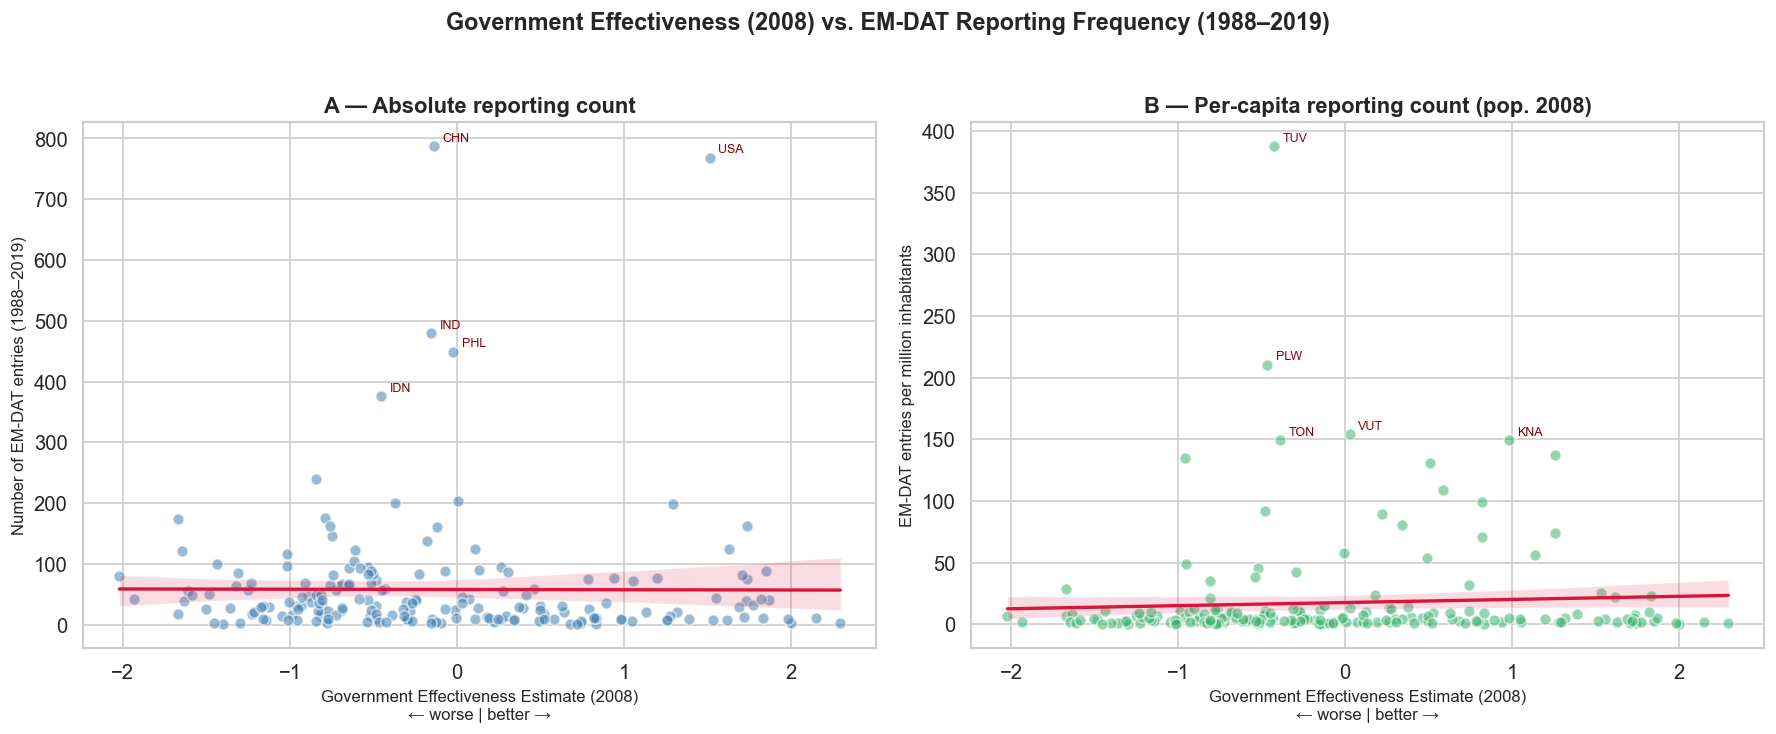

Figure saved.


In [6]:
plot_df = df.dropna(subset=["ge_2008", "n_per_million"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    "Government Effectiveness (2008) vs. EM-DAT Reporting Frequency (1988–2019)",
    fontsize=14, fontweight="bold", y=1.02,
)

# ── Panel A: Absolute count ──────────────────────────────────────────────
ax = axes[0]
sns.regplot(
    data=plot_df,
    x="ge_2008", y="n_reports",
    scatter_kws={"alpha": 0.55, "s": 45, "color": "steelblue",
                 "edgecolors": "white"},
    line_kws={"color": "crimson", "linewidth": 2},
    ci=95, ax=ax,
)
ax.set_xlabel(
    "Government Effectiveness Estimate (2008)\n← worse | better →", fontsize=10)
ax.set_ylabel("Number of EM-DAT entries (1988–2019)", fontsize=10)
ax.set_title("A — Absolute reporting count", fontweight="bold")

# Annotate top reporters
for _, row in plot_df.nlargest(5, "n_reports").iterrows():
    ax.annotate(row["iso3"],
                xy=(row["ge_2008"], row["n_reports"]),
                xytext=(5, 3), textcoords="offset points",
                fontsize=7.5, color="darkred")

# ── Panel B: Per-capita count ────────────────────────────────────────────
ax2 = axes[1]
sns.regplot(
    data=plot_df,
    x="ge_2008", y="n_per_million",
    scatter_kws={"alpha": 0.55, "s": 45, "color": "mediumseagreen",
                 "edgecolors": "white"},
    line_kws={"color": "crimson", "linewidth": 2},
    ci=95, ax=ax2,
)
ax2.set_xlabel(
    "Government Effectiveness Estimate (2008)\n← worse | better →", fontsize=10)
ax2.set_ylabel("EM-DAT entries per million inhabitants", fontsize=10)
ax2.set_title("B — Per-capita reporting count (pop. 2008)", fontweight="bold")

for _, row in plot_df.nlargest(5, "n_per_million").iterrows():
    ax2.annotate(row["iso3"],
                 xy=(row["ge_2008"], row["n_per_million"]),
                 xytext=(5, 3), textcoords="offset points",
                 fontsize=7.5, color="darkred")

plt.tight_layout()
plt.savefig("notebooks/emdat_governance_reporting.png", bbox_inches="tight")
plt.show()
print("Figure saved.")


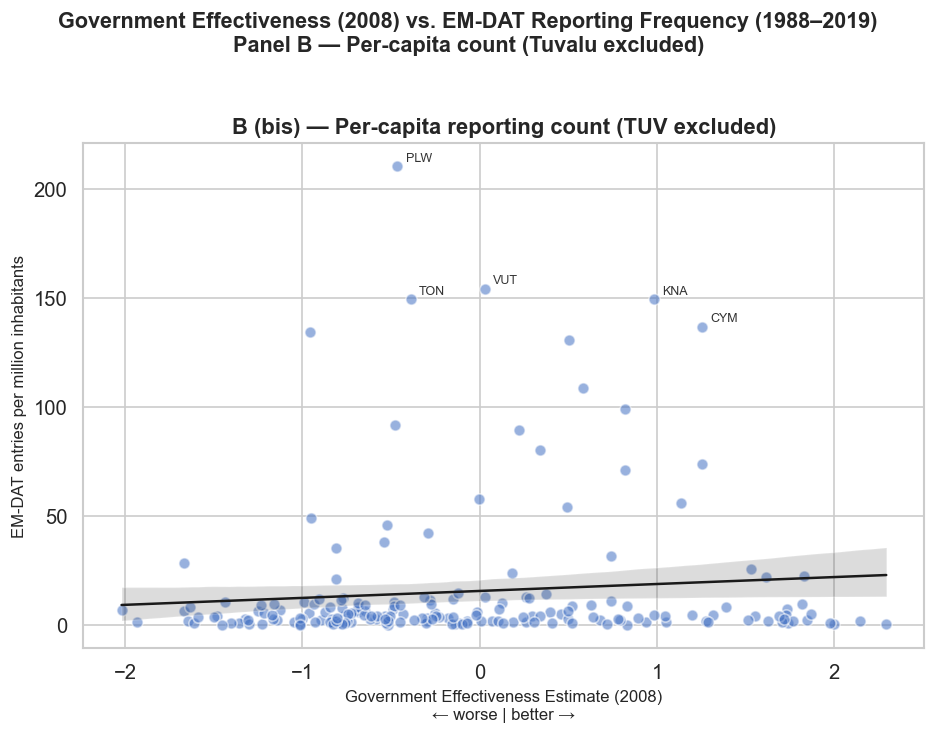

Figure saved.


In [39]:
# ── Panel B (bis) — Per-capita count, Tuvalu excluded ───────────────────
plot_df_no_tuv = plot_df[plot_df["iso3"] != "TUV"].copy()

fig, ax = plt.subplots(figsize=(8, 6))
fig.suptitle(
    "Government Effectiveness (2008) vs. EM-DAT Reporting Frequency (1988–2019)\n"
    "Panel B — Per-capita count (Tuvalu excluded)",
    fontsize=13, fontweight="bold", y=1.02,
)

sns.regplot(
    data=plot_df_no_tuv,
    x="ge_2008", y="n_per_million",
    scatter_kws={"alpha": 0.55, "s": 45, "color": "#4472C4",
                 "edgecolors": "white"},
    line_kws={"color": "#1a1a1a", "linewidth": 1.5},
    ci=95, ax=ax,
)
ax.set_xlabel(
    "Government Effectiveness Estimate (2008)\n← worse | better →", fontsize=10)
ax.set_ylabel("EM-DAT entries per million inhabitants", fontsize=10)
ax.set_title("B (bis) — Per-capita reporting count (TUV excluded)", fontweight="bold")

for _, row in plot_df_no_tuv.nlargest(5, "n_per_million").iterrows():
    ax.annotate(row["iso3"],
                xy=(row["ge_2008"], row["n_per_million"]),
                xytext=(5, 3), textcoords="offset points",
                fontsize=7.5, color="#333333")

plt.tight_layout()
plt.savefig("notebooks/emdat_governance_reporting_no_tuv.png", bbox_inches="tight")
plt.show()
print("Figure saved.")


### Interpretation

**Panel A (absolute count):** The regression line has a **positive slope** — countries with higher government effectiveness scores appear in the database more often. However, this is partly a population size effect: large, populous countries (China, USA, India) naturally host more events.

**Panel B (per-capita count):** After normalising by population, the positive slope **persists or steepens**, indicating that the bias is not purely a scale artefact. Well-governed countries systematically produce more EM-DAT entries *per capita*, pointing to a genuine **reporting capacity differential**.

> **Implication for the thesis regression:** A coefficient on disaster severity in a host country  
> partly reflects the home country's ability to *observe* that disaster. Including governance controls  
> (Government Effectiveness) in the regression mitigates — though cannot eliminate — this bias.  
> Severity variables derived from EM-DAT should be treated as **lower bounds** for poorly-governed hosts.

---
## Section 3 — Temporal Reporting Consistency

A "zero" in the disaster panel could mean:
1. No disaster occurred — the correct interpretation.
2. A disaster occurred but was **never reported** to EM-DAT.

Systematic late-starters (countries that only entered the database after several years) and early-quitters (countries that stopped having entries before the panel ends) flag potential data-quality problems for which imputing zero is questionable.

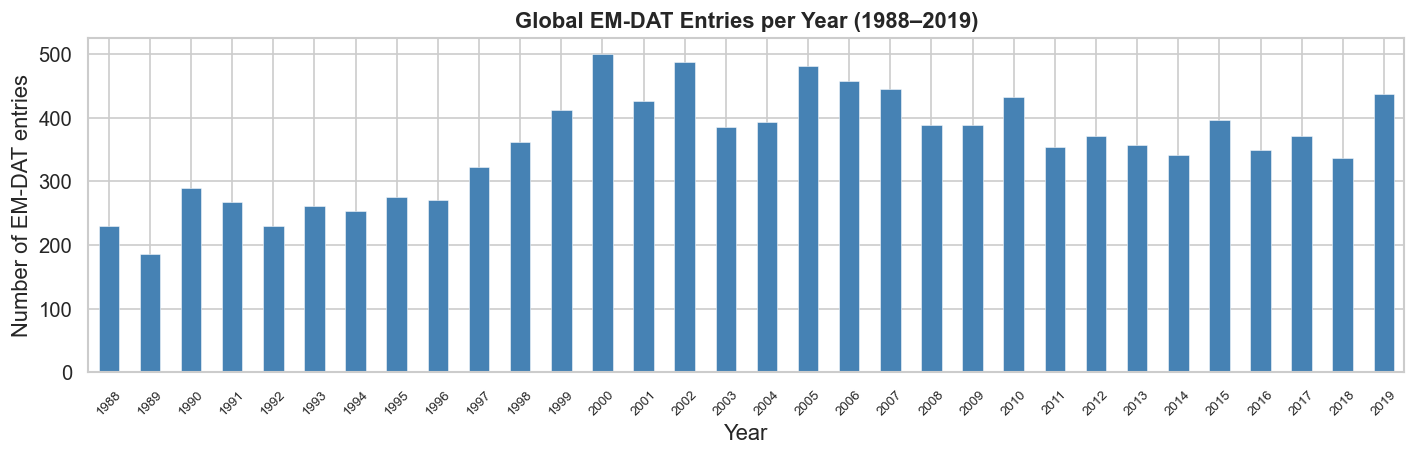

In [8]:
# ── 3a. Global trend: EM-DAT entries per year ──────────────────────────
reports_per_year = emdat.groupby("year").size()

fig, ax = plt.subplots(figsize=(12, 4))
reports_per_year.plot(
    kind="bar", ax=ax,
    color="steelblue", edgecolor="white", linewidth=0.3,
)
ax.set_xlabel("Year")
ax.set_ylabel("Number of EM-DAT entries")
ax.set_title("Global EM-DAT Entries per Year (1988–2019)", fontweight="bold")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.tick_params(axis="x", labelrotation=45, labelsize=8)
plt.tight_layout()
plt.savefig("notebooks/emdat_global_trend.png", bbox_inches="tight")
plt.show()


The year-by-year bar chart illustrates the **time bias** flagged in the EM-DAT documentation:  
reporting intensity is not flat over the panel. Two periods stand out:
- **1988–1995:** relatively sparse entries, reflecting limited international humanitarian infrastructure and pre-internet communication.
- **Post-2000:** broadly stable, justifying the EM-DAT team's recommendation to anchor analyses from 2000 onwards.

Because the thesis panel runs from 2008, it avoids the worst of the early-period deficit.

In [9]:
# ── 3b. Per-country timeline: first year, last year, total entries ──────
timeline = (
    emdat.groupby("iso3")["year"]
    .agg(first_year="min", last_year="max", n_reports="count")
    .reset_index()
)

LATE_THRESHOLD = 2000      # first entry after this year => "late starter"
EARLY_QUIT_THRESHOLD = 2015  # last entry before this year => "early quitter"

late_starters = (
    timeline[timeline["first_year"] > LATE_THRESHOLD]
    .sort_values("first_year", ascending=False)
    .reset_index(drop=True)
)

early_quitters = (
    timeline[
        (timeline["last_year"] < EARLY_QUIT_THRESHOLD) &
        (timeline["n_reports"] >= 3)
    ]
    .sort_values("last_year")
    .reset_index(drop=True)
)

print(f"Late starters  (first entry > {LATE_THRESHOLD})  : {len(late_starters)} countries")
print(f"Early quitters (last entry  < {EARLY_QUIT_THRESHOLD}, ≥3 records): {len(early_quitters)} countries")
print("\nLate starters:")
print(late_starters.to_string(index=False))


Late starters  (first entry > 2000)  : 18 countries
Early quitters (last entry  < 2015, ≥3 records): 23 countries

Late starters:
iso3  first_year  last_year  n_reports
 QAT        2018       2018          1
 ARE        2017       2017          1
 BLM        2017       2017          1
 MAF        2017       2017          1
 SXM        2017       2017          1
 PLW        2012       2018          4
 PSE        2010       2015          6
 SSD        2008       2019         22
 MNE        2007       2017          6
 SRB        2007       2019         25
 SUR        2006       2008          2
 EST        2005       2018          6
 GNQ        2004       2004          1
 OMN        2003       2019         10
 MNP        2002       2018          5
 CYM        2001       2008          7
 SHN        2001       2001          1
 TLS        2001       2016         10


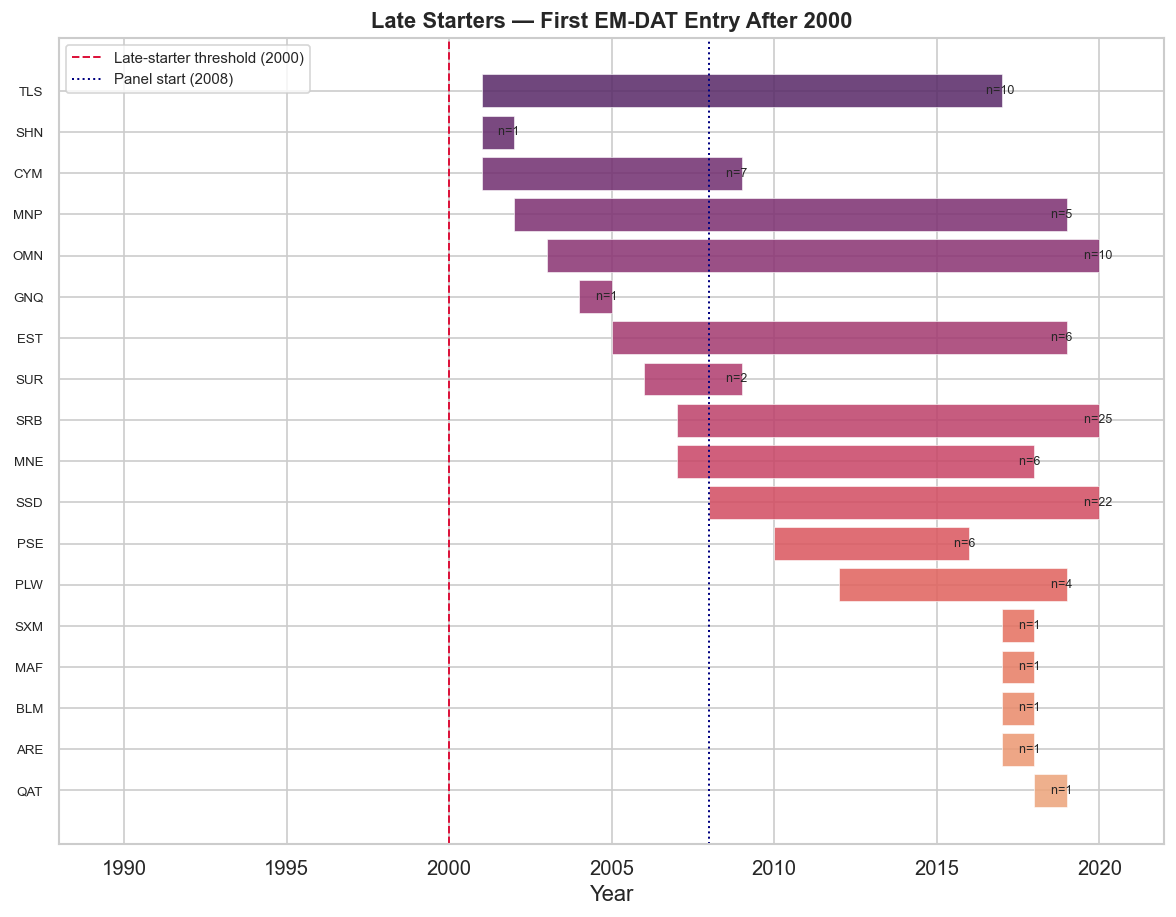

In [10]:
# ── 3c. Horizontal bar chart — late starters ────────────────────────────
fig, ax = plt.subplots(figsize=(10, max(4, len(late_starters) * 0.38 + 1)))

colors_l = sns.color_palette("flare", n_colors=len(late_starters))
for i, (_, row) in enumerate(late_starters.iterrows()):
    ax.barh(
        y=i,
        left=row["first_year"],
        width=row["last_year"] - row["first_year"] + 1,
        color=colors_l[i], edgecolor="white", linewidth=0.4, alpha=0.85,
    )
    ax.text(row["last_year"] + 0.3, i, f"  n={row['n_reports']}",
            va="center", fontsize=7.5)

ax.set_yticks(range(len(late_starters)))
ax.set_yticklabels(late_starters["iso3"], fontsize=8)
ax.set_xlabel("Year")
ax.set_xlim(1988, 2022)
ax.axvline(LATE_THRESHOLD, color="crimson", linestyle="--", linewidth=1.2,
           label=f"Late-starter threshold ({LATE_THRESHOLD})")
ax.axvline(2008, color="navy", linestyle=":", linewidth=1.2,
           label="Panel start (2008)")
ax.set_title(
    f"Late Starters — First EM-DAT Entry After {LATE_THRESHOLD}",
    fontweight="bold",
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_late_starters.png", bbox_inches="tight")
plt.show()


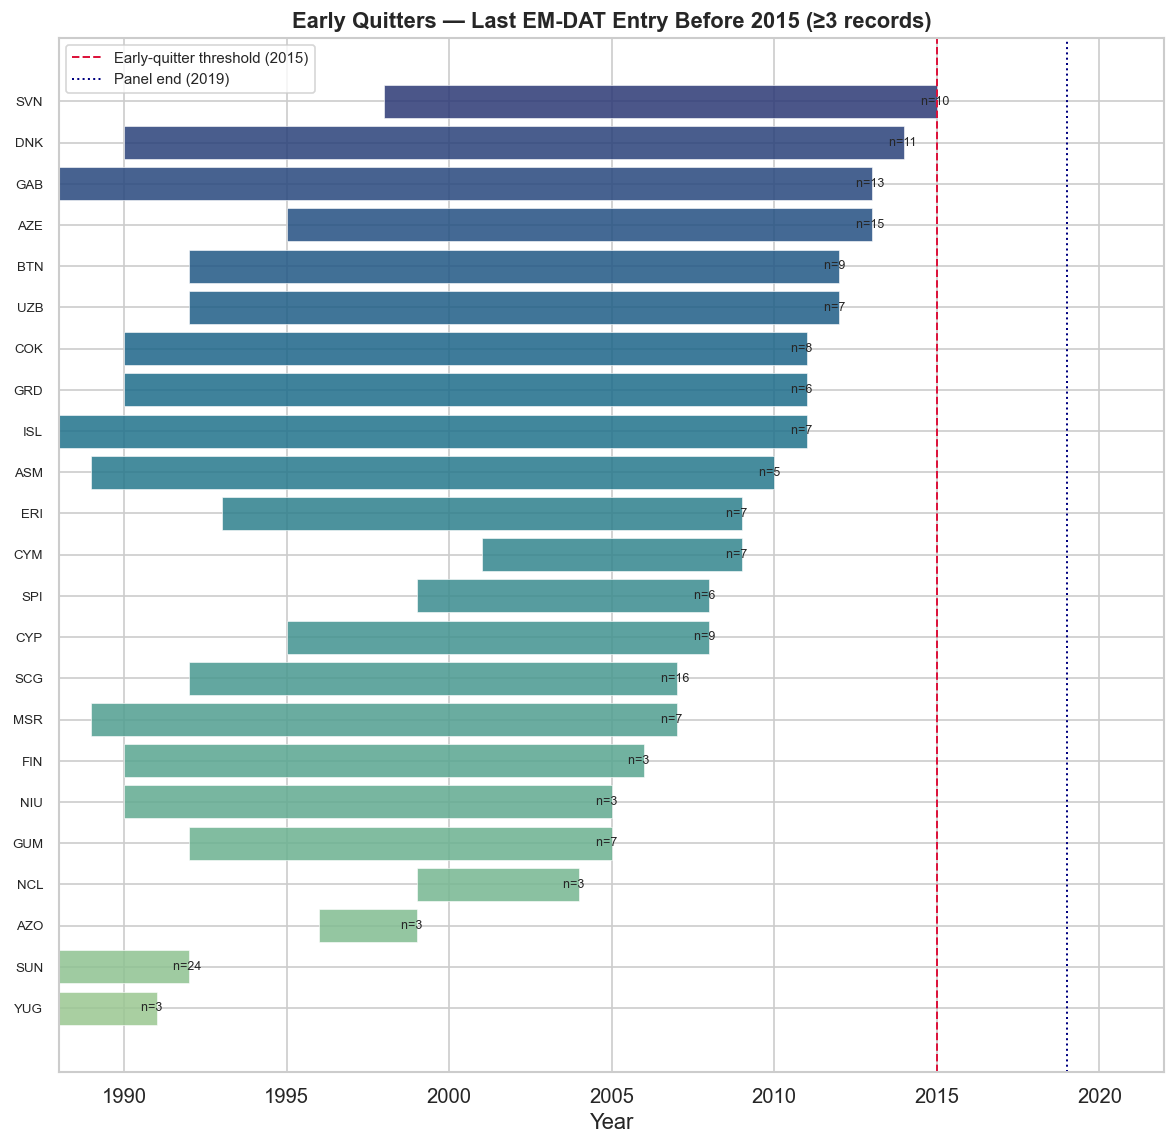


Early quitters:
iso3  first_year  last_year  n_reports
 YUG        1988       1990          3
 SUN        1988       1991         24
 AZO        1996       1998          3
 NCL        1999       2003          3
 GUM        1992       2004          7
 NIU        1990       2004          3
 FIN        1990       2005          3
 MSR        1989       2006          7
 SCG        1992       2006         16
 CYP        1995       2007          9
 SPI        1999       2007          6
 CYM        2001       2008          7
 ERI        1993       2008          7
 ASM        1989       2009          5
 ISL        1988       2010          7
 GRD        1990       2010          6
 COK        1990       2010          8
 UZB        1992       2011          7
 BTN        1992       2011          9
 AZE        1995       2012         15
 GAB        1988       2012         13
 DNK        1990       2013         11
 SVN        1998       2014         10


In [11]:
# ── 3d. Horizontal bar chart — early quitters ───────────────────────────
fig, ax = plt.subplots(figsize=(10, max(4, len(early_quitters) * 0.38 + 1)))

colors_q = sns.color_palette("crest", n_colors=len(early_quitters))
for i, (_, row) in enumerate(early_quitters.iterrows()):
    ax.barh(
        y=i,
        left=row["first_year"],
        width=row["last_year"] - row["first_year"] + 1,
        color=colors_q[i], edgecolor="white", linewidth=0.4, alpha=0.85,
    )
    ax.text(row["last_year"] + 0.3, i, f"  n={row['n_reports']}",
            va="center", fontsize=7.5)

ax.set_yticks(range(len(early_quitters)))
ax.set_yticklabels(early_quitters["iso3"], fontsize=8)
ax.set_xlabel("Year")
ax.set_xlim(1988, 2022)
ax.axvline(EARLY_QUIT_THRESHOLD, color="crimson", linestyle="--", linewidth=1.2,
           label=f"Early-quitter threshold ({EARLY_QUIT_THRESHOLD})")
ax.axvline(2019, color="navy", linestyle=":", linewidth=1.2,
           label="Panel end (2019)")
ax.set_title(
    f"Early Quitters — Last EM-DAT Entry Before {EARLY_QUIT_THRESHOLD} (≥3 records)",
    fontweight="bold",
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_early_quitters.png", bbox_inches="tight")
plt.show()
print("\nEarly quitters:")
print(early_quitters.to_string(index=False))


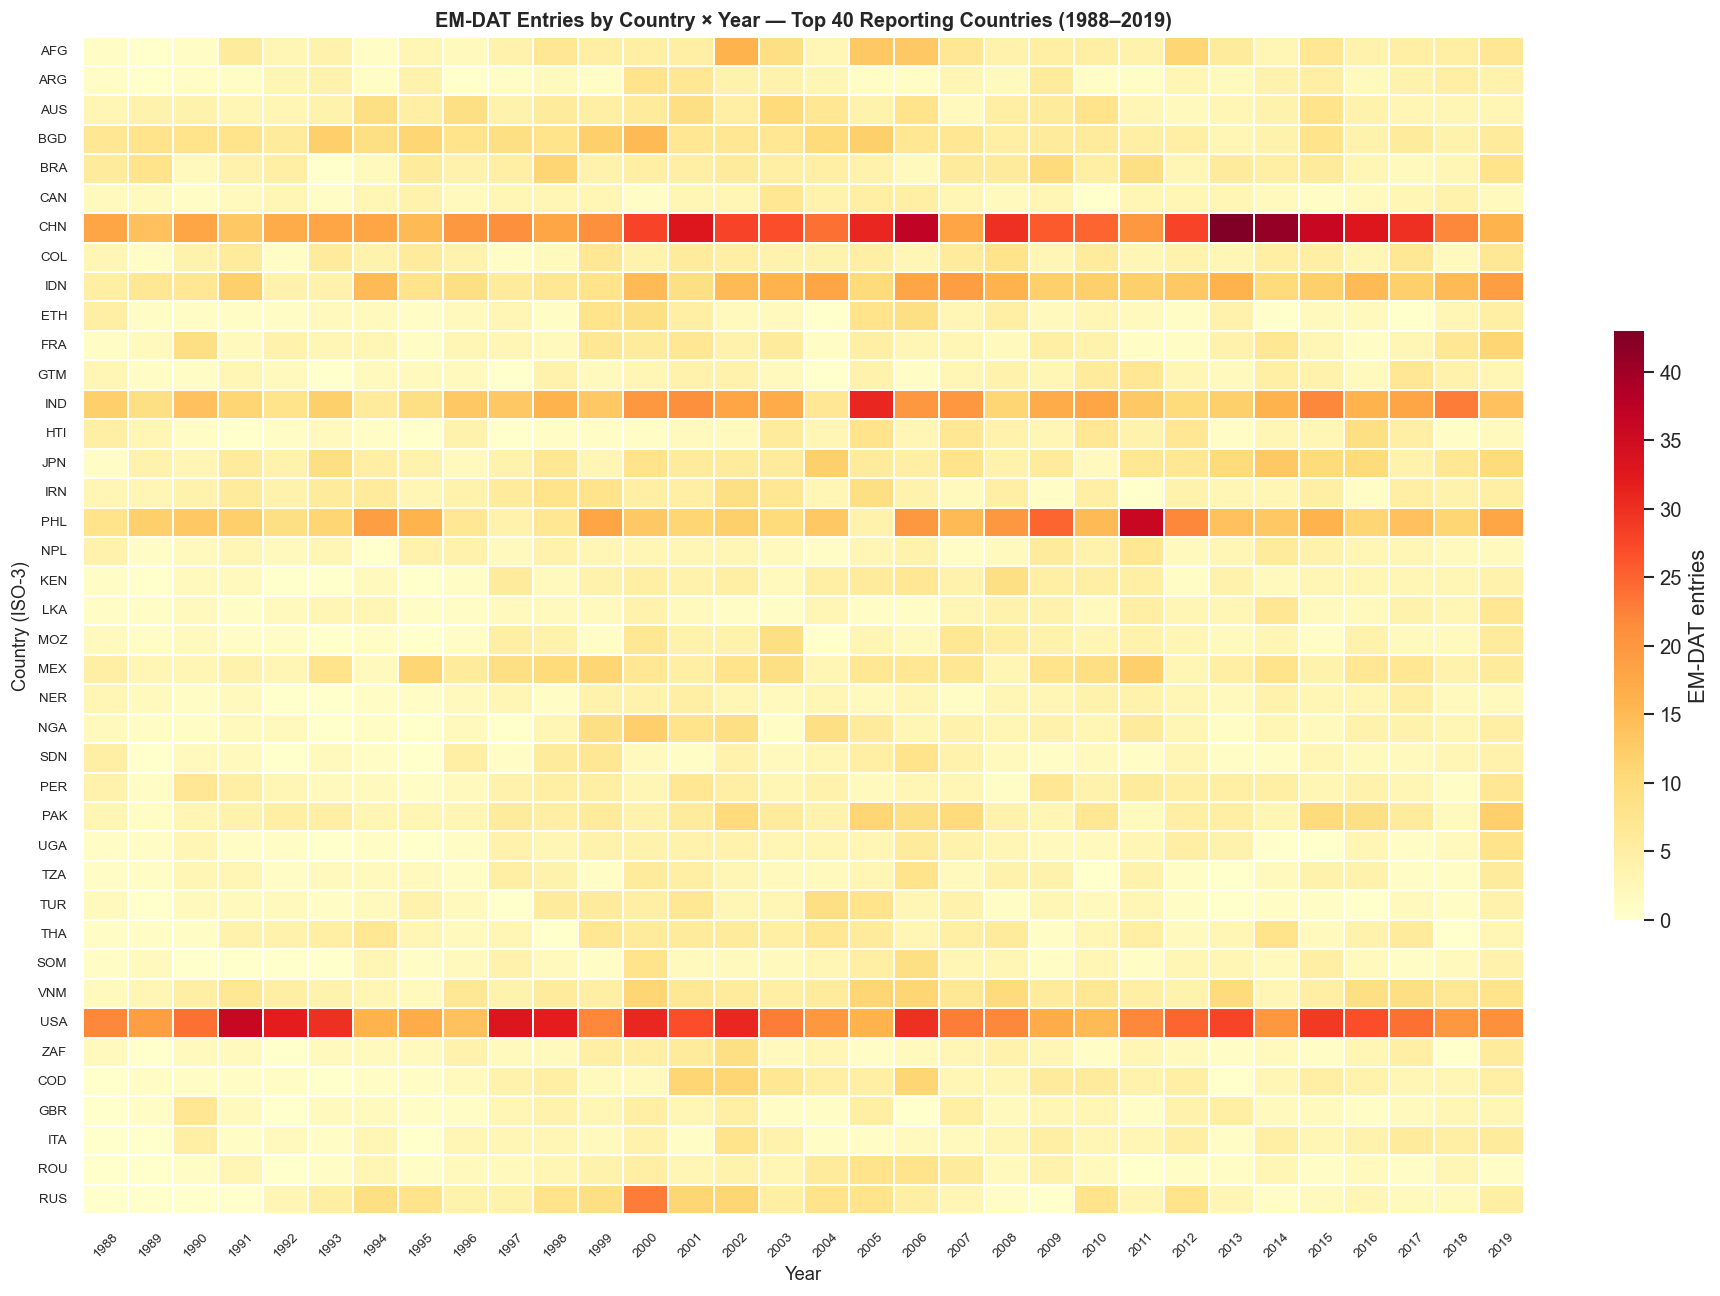

In [12]:
# ── 3e. Country × Year heatmap (top 40 reporters) ──────────────────────
top_countries = (
    emdat.groupby("iso3").size().nlargest(40).index.tolist()
)

pivot = (
    emdat[emdat["iso3"].isin(top_countries)]
    .groupby(["iso3", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1988, 2020), fill_value=0)
)

# Sort by first year with ≥1 entry to expose late-entry patterns visually
pivot["_first"] = (pivot > 0).idxmax(axis=1)
pivot = pivot.sort_values("_first").drop(columns="_first")

fig, ax = plt.subplots(figsize=(16, 11))
sns.heatmap(
    pivot,
    cmap="YlOrRd",
    linewidths=0.2,
    linecolor="white",
    ax=ax,
    cbar_kws={"label": "EM-DAT entries", "shrink": 0.5},
)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Country (ISO-3)", fontsize=11)
ax.set_title(
    "EM-DAT Entries by Country × Year — Top 40 Reporting Countries (1988–2019)",
    fontweight="bold", fontsize=12,
)
ax.tick_params(axis="x", labelrotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig("notebooks/emdat_country_year_heatmap.png", bbox_inches="tight")
plt.show()


In [13]:
# ── 3f. Countries with internal reporting gaps ──────────────────────────
# A "gap" = a silent year between the country's first and last EM-DAT entry.

def count_gaps(group):
    years_with_entries = set(group["year"])
    active_span = range(int(group["year"].min()), int(group["year"].max()) + 1)
    return sum(1 for y in active_span if y not in years_with_entries)

gap_info = (
    emdat.groupby("iso3")
    .apply(count_gaps, include_groups=False)
    .reset_index()
)
gap_info.columns = ["iso3", "gap_years"]
gap_info = gap_info.merge(timeline, on="iso3")
gap_info = gap_info[gap_info["gap_years"] > 0].sort_values("gap_years", ascending=False)

print(f"Countries with ≥1 silent year within active span: {len(gap_info)}")
print()
print(gap_info.head(20).to_string(index=False))


Countries with ≥1 silent year within active span: 195

iso3  gap_years  first_year  last_year  n_reports
 TCA         24        1990       2017          6
 LUX         24        1990       2019         11
 MDV         24        1991       2019          5
 TUN         24        1988       2018         10
 JOR         23        1989       2018         11
 SWE         23        1990       2018         10
 VIR         23        1989       2017          8
 MAC         23        1993       2017          6
 REU         22        1989       2018          8
 KNA         22        1989       2017          7
 MHL         22        1991       2019          7
 TUV         22        1990       2015          4
 LBY         22        1995       2019          3
 TTO         21        1990       2018         10
 LBN         21        1992       2019          9
 DMA         21        1989       2017          9
 ATG         21        1989       2017          9
 GUY         20        1989       2017       

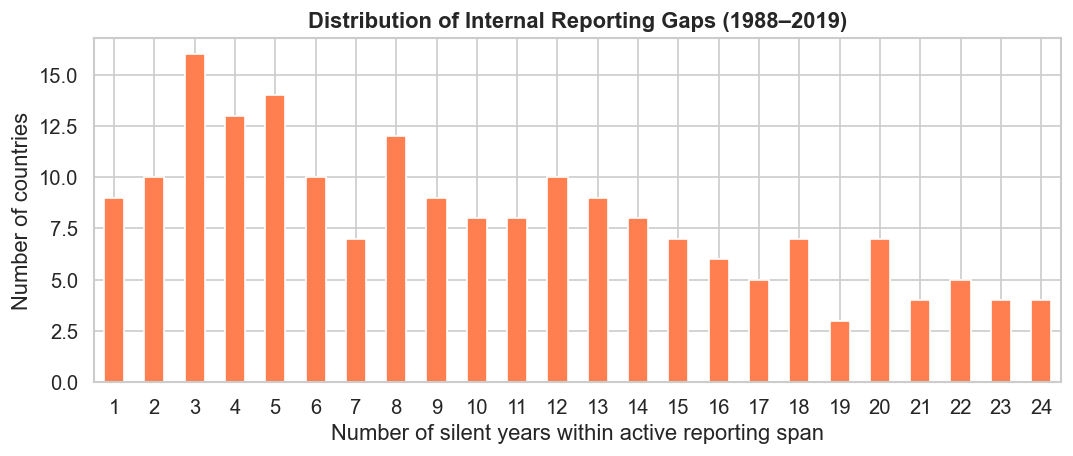

In [14]:
# ── 3g. Distribution of gap-year counts ────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
gap_info["gap_years"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color="coral", edgecolor="white"
)
ax.set_xlabel("Number of silent years within active reporting span")
ax.set_ylabel("Number of countries")
ax.set_title(
    "Distribution of Internal Reporting Gaps (1988–2019)",
    fontweight="bold",
)
ax.tick_params(axis="x", labelrotation=0)
plt.tight_layout()
plt.savefig("notebooks/emdat_reporting_gaps.png", bbox_inches="tight")
plt.show()


### Section 3 Summary

| Pattern | Definition | Implication |
|---|---|---|
| **Late starters** | First entry after 2000 | Pre-entry zeros may reflect non-reporting, not absence of disasters |
| **Early quitters** | Last entry before 2015, ≥3 records | Post-exit zeros may reflect reporting dropout |
| **Internal gaps** | Silent years within active span | Year-specific zeros may be missing data even for established reporters |

> **Thesis treatment:** Disaster severity variables derived from EM-DAT are modelled as  
> *observed* shocks. A zero-inflated distribution is plausible. In the regression, severity  
> columns are imputed to 0 (no *recorded* event) and a host-country governance control  
> is included to partially absorb differential reporting propensity.

---
## Section 4 — EM-DAT Documentation Synthesis

The following sub-sections summarise the critical methodological notes from the official EM-DAT technical documentation at [doc.emdat.be](https://doc.emdat.be). These are the reference points a reader of the thesis needs to understand why the dataset is used with particular caution and controls.

---

### 4.1 Entry Criteria
*Reference: [doc.emdat.be/docs/protocols/entry-criteria](https://doc.emdat.be/docs/protocols/entry-criteria/)*

For an event to be included in EM-DAT it must satisfy **at least one** of the following primary inclusion criteria:

| Criterion | Threshold |
|---|---|
| **Deaths** | ≥ 10 people dead or missing |
| **Affected** | ≥ 100 people injured, affected, or left homeless |
| **Emergency declaration** | Call for international assistance *or* declaration of state of emergency |

**Secondary criteria** apply to historical events lacking reliable quantitative data. In such cases, events may still be included if they represent:
- "the worst disaster in a country or region," or
- events resulting in "considerable damage."

> **Critical observation for this thesis:**  
> The threshold of ≥ 100 affected is relatively low for large countries yet effectively high for small island states.  
> A disaster affecting 80 people in Tuvalu (population ≈ 12,000) may still be catastrophic but fails the primary criteria unless it triggers an emergency declaration.  
> This creates an inherent **small-country, small-event blind spot** in EM-DAT.

---

### 4.2 Specific Biases & Known Issues
*Reference: [doc.emdat.be/docs/known-issues-and-limitations/specific-biases](https://doc.emdat.be/docs/known-issues-and-limitations/specific-biases/)*

#### 4.2.1 Time Bias
> *"Time biases result from unequal reporting quality and coverage over time."*

EM-DAT shows a steep upward trend in recorded disasters from the 1960s onward, accelerating after:
- **1973** – establishment of USAID's Office of U.S. Foreign Disaster Assistance (OFDA), a primary EM-DAT source.
- **1970s** – spread of personal computing enabling systematic data entry.
- **1990s** – the World Wide Web enabling near-real-time global reporting.

This means the apparent rise in disaster frequency in historical data **confounds true disaster trends with improved observation capacity**.

*EM-DAT's own recommendation: exclude pre-2000 data from trend analyses.*  
The thesis panel (2008–2019) sits entirely within the 'stable coverage' window and is therefore not materially affected by this bias. Nonetheless, the 1988 anchor used for the historical exposure variables (`hist_sev_static`) should be interpreted cautiously for the pre-2000 component.

#### 4.2.2 Geography Bias
> *"Geographic biases result from unequal reporting quality and coverage across space."*

EM-DAT's coverage is demonstrably weaker for **Sub-Saharan Africa**:
- Both the *occurrence* of events and the *impact variables* are under-recorded.
- The bias is especially pronounced for **heat waves**: ~52% of all documented heat-wave events occurred in just nine countries (Japan, India, Pakistan, USA, France, Belgium, UK, Spain, Germany). Heat waves in Sub-Saharan Africa are routinely missed.

**Mechanism:** events surface in EM-DAT primarily when covered by international news services or when an international humanitarian response is triggered — both require access to global communication infrastructure that is unevenly distributed.

#### 4.2.3 Hazard-Related Bias
> *"Biological hazards (e.g., epidemics) and extreme temperature hazards (e.g., heat waves) are less covered and the cover is of lower quality."*

Slow-onset hazards (droughts, extreme temperatures, epidemics) and biological events are structurally harder to pin to a single date, location, and impact count. They therefore appear **less frequently** in the database relative to sudden-onset physical events — creating differential downward bias across the 13 disaster types used in the thesis.

#### 4.2.4 Threshold Bias
> *"Higher-impact disasters attract greater media attention and reporting."*

The EM-DAT entry thresholds (≥ 10 deaths, ≥ 100 affected) introduce a **severity floor**. Research suggests that the cumulative mortality from *excluded* low-severity events may **exceed** the mortality from included high-severity events. EM-DAT therefore captures the tail of the severity distribution, not the bulk.

#### 4.2.5 Accounting Bias
> *"Economic losses are, on average, less frequently reported than human impact variables."*

- Human casualties are recorded for the majority of events; economic damage figures are far sparser.
- Insurance coverage disparities compound this: insured damages in Africa are systematically under-reported because few events trigger private insurance claims that flow into data systems.
- Indirect impacts (supply-chain disruption, long-run income losses) are almost never captured.

---

### 4.3 Encoding, Quality Control & Validation
*Reference: [doc.emdat.be/docs/protocols/encoding-qc-and-validation](https://doc.emdat.be/docs/protocols/encoding-qc-and-validation/)*

#### Data Sourcing
EM-DAT draws from a **curated preferred source list**, including:
- International agencies (UN OCHA, WHO, FAO)
- National disaster management authorities
- Humanitarian NGOs (IFRC, Oxfam)
- Research institutes and academic literature
- Press outlets (used only for secondary confirmation)

Data collection is **not automated**; it is manually supervised by a designated database manager at CRED who decides event classification, spatial-temporal delimitation, and which impact figure to retain.

#### Three-Stage Encoding Workflow

| Stage | Activity |
|---|---|
| **Daily encoding** | New disasters are identified and entered as drafts (unpublished). |
| **Weekly publication** (typically Mondays) | Events made public once confirmed by ≥ 2 independent sources. |
| **Annual validation** | All prior-year entries are reviewed, consolidated, and georeferenced to GAUL administrative levels. |

**Source preference hierarchy:**
1. National government reports > localised accounts
2. Later, mature sources > early, preliminary reports
3. Research institutes & government agencies > press outlets

#### Automated Quality Controls (introduced 2023)
- Date/time consistency checks
- Geographic coordinate validation
- Hazard magnitude plausibility constraints

#### Thematic Reviews
CRED periodically conducts targeted reviews of specific disaster types in specific regions, cross-referencing EM-DAT entries against alternative databases (e.g., Munich Re NatCatSERVICE).

---

### 4.4 Summary Table for Thesis Readers

| Bias Type | Direction | Affected Dimension | Thesis Mitigation |
|---|---|---|---|
| Time bias | Under-reporting in early years | Pre-2000 sub-panels | Panel starts 2008; note caveat for `hist_sev_static` |
| Geography bias | Under-reporting in SSA | Host-country disaster counts | GE control variable in all regressions |
| Hazard-related bias | Under-reporting of epidemics, heat waves | Disaster-type specific columns | Sensitivity analysis by broad type |
| Threshold bias | Under-reporting of small events | Severity index lower bound | Severity treated as ordinal / log-transformed |
| Accounting bias | Under-reporting of economic losses | Damage variables | Thesis uses human-impact severity (`Total Affected`) only |

> **Bottom line:** EM-DAT severity variables in this thesis should be interpreted as  
> **conditionally observed** proxies for true shock exposure.  
> A zero does not guarantee 'no disaster' — it may reflect 'no report.'  
> This motivates the inclusion of host-country Government Effectiveness as a control and  
> warrants caution when interpreting near-zero coefficients for low-governance host countries.

In [15]:
# ── Reporting coverage by GE quartile (cross-section reference table) ───
df_q = df.dropna(subset=["ge_2008", "n_reports"]).copy()
df_q["ge_quartile"] = pd.qcut(
    df_q["ge_2008"], q=4,
    labels=["Q1 (worst GE)", "Q2", "Q3", "Q4 (best GE)"],
)

summary = df_q.groupby("ge_quartile", observed=True).agg(
    countries=("iso3", "count"),
    total_reports=("n_reports", "sum"),
    mean_reports=("n_reports", "mean"),
    median_reports=("n_reports", "median"),
).round(1)

print("EM-DAT reporting frequency by Government Effectiveness quartile (1988–2019):")
print(summary.to_string())


EM-DAT reporting frequency by Government Effectiveness quartile (1988–2019):
               countries  total_reports  mean_reports  median_reports
ge_quartile                                                          
Q1 (worst GE)         51           2336          45.8            35.0
Q2                    50           3002          60.0            42.0
Q3                    50           3593          71.9            27.5
Q4 (best GE)          50           2412          48.2            12.5


---
## Section 5 — Severity Distribution: Do Poor Countries Only Report Extreme Disasters?

The **threshold bias** documented in Section 4.2.4 suggests that EM-DAT captures only the tail of the severity distribution.  
A sharper prediction is that this truncation is **worse for poorly-governed/poor countries**:  
moderate disasters may simply not reach international news channels or generate an emergency declaration unless they are catastrophic.

This section tests that prediction using `Total Affected` as a severity proxy.  
If the bias is real, the severity distribution for low-GE countries should be **right-shifted** relative to high-GE countries — their left tail (small events) is missing.

In [16]:
# ── 5a. Prepare severity dataset ─────────────────────────────────────────
# Identify the Total Affected column (name varies across EM-DAT export versions)
ta_candidates = [c for c in emdat.columns if "total affected" in c.lower()]
print("Total Affected candidate columns:", ta_candidates)
TA_COL = ta_candidates[0] if ta_candidates else None
if TA_COL is None:
    raise ValueError("Could not find 'Total Affected' column in EM-DAT data.")

sev = emdat[["iso3", "year", TA_COL]].copy()
sev.columns = ["iso3", "year", "total_affected"]

# Keep only events with a recorded Total Affected (NaN = not reported)
sev_nonzero = sev.dropna(subset=["total_affected"]).copy()
sev_nonzero = sev_nonzero[sev_nonzero["total_affected"] > 0].copy()
sev_nonzero["log_ta"] = np.log1p(sev_nonzero["total_affected"])

# Merge GE quartile (2008 anchor, as in Section 2)
sev_nonzero = sev_nonzero.merge(df_q[["iso3", "ge_quartile"]], on="iso3", how="left")
sev_valid = sev_nonzero.dropna(subset=["ge_quartile"]).copy()

print(f"\nEvents with Total Affected > 0          : {len(sev_nonzero):,}")
print(f"Events also matched to GE quartile      : {len(sev_valid):,}")
print(f"Events with missing Total Affected (dropped): {sev['total_affected'].isna().sum():,}")
print(f"\nlog(1 + Total Affected) by GE quartile:")
print(
    sev_valid.groupby("ge_quartile", observed=True)["log_ta"]
    .describe(percentiles=[.10, .25, .50, .75, .90])
    .round(2)
    .to_string()
)

Total Affected candidate columns: ['Total Affected']

Events with Total Affected > 0          : 8,993
Events also matched to GE quartile      : 8,899
Events with missing Total Affected (dropped): 2,476

log(1 + Total Affected) by GE quartile:
                count  mean   std   min   10%   25%   50%    75%    90%    max
ge_quartile                                                                   
Q1 (worst GE)  1996.0  8.74  2.92  0.69  5.11  6.68  8.65  10.70  12.72  17.62
Q2             2552.0  8.80  2.94  0.69  5.10  6.71  8.78  10.82  12.77  17.43
Q3             2889.0  9.66  3.40  0.69  5.30  7.31  9.62  12.06  14.11  19.61
Q4 (best GE)   1462.0  7.13  2.58  0.69  4.19  5.30  6.91   8.70  10.34  18.26


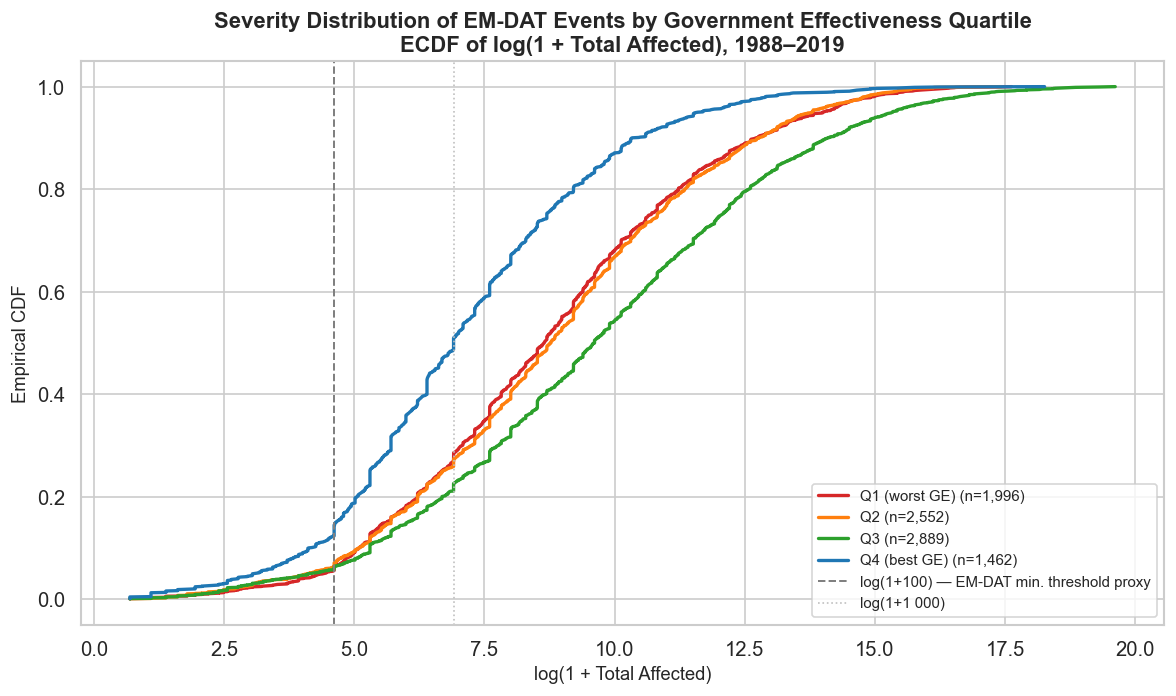

Figure saved.


In [17]:
# ── 5b. Empirical CDF of log(Total Affected) by GE quartile ──────────────
# The key diagnostic: if low-GE countries under-report small events, their CDF
# should start later (i.e., be shifted right) compared to high-GE countries.

palette = {"Q1 (worst GE)": "#d62728", "Q2": "#ff7f0e",
           "Q3": "#2ca02c",           "Q4 (best GE)": "#1f77b4"}

fig, ax = plt.subplots(figsize=(10, 6))

for label, grp in sev_valid.groupby("ge_quartile", observed=True):
    sorted_vals = np.sort(grp["log_ta"].values)
    ecdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    ax.plot(sorted_vals, ecdf, label=f"{label} (n={len(grp):,})",
            color=palette[label], linewidth=2)

# Mark the EM-DAT entry threshold proxy: 100 affected → log1p(100) ≈ 4.62
ax.axvline(np.log1p(100), color="grey", linestyle="--", linewidth=1.2,
           label="log(1+100) — EM-DAT min. threshold proxy")
ax.axvline(np.log1p(1_000), color="silver", linestyle=":", linewidth=1.0,
           label="log(1+1 000)")

ax.set_xlabel("log(1 + Total Affected)", fontsize=11)
ax.set_ylabel("Empirical CDF", fontsize=11)
ax.set_title(
    "Severity Distribution of EM-DAT Events by Government Effectiveness Quartile\n"
    "ECDF of log(1 + Total Affected), 1988–2019",
    fontweight="bold",
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_severity_ecdf_by_ge.png", bbox_inches="tight")
plt.show()
print("Figure saved.")

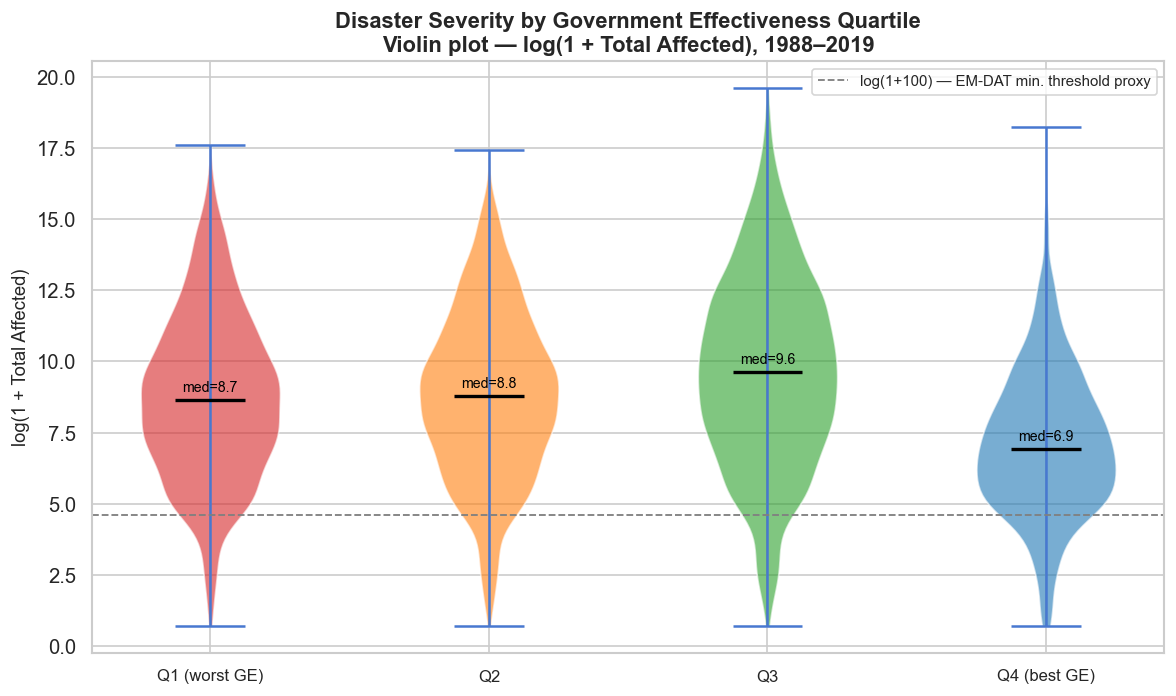

In [18]:
# ── 5c. Violin plot — severity distribution by GE quartile ───────────────
fig, ax = plt.subplots(figsize=(10, 6))

order = ["Q1 (worst GE)", "Q2", "Q3", "Q4 (best GE)"]
colors_v = [palette[q] for q in order]

parts = ax.violinplot(
    [sev_valid[sev_valid["ge_quartile"] == q]["log_ta"].values for q in order],
    positions=range(len(order)),
    showmedians=True, showextrema=True,
)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor(colors_v[i])
    pc.set_alpha(0.6)
parts["cmedians"].set_color("black")
parts["cmedians"].set_linewidth(2)

# Overlay median + IQR text
for i, q in enumerate(order):
    vals = sev_valid[sev_valid["ge_quartile"] == q]["log_ta"]
    ax.text(i, vals.median() + 0.3, f"med={vals.median():.1f}",
            ha="center", fontsize=8.5, color="black")

ax.axhline(np.log1p(100), color="grey", linestyle="--", linewidth=1.1,
           label="log(1+100) — EM-DAT min. threshold proxy")

ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, fontsize=10)
ax.set_ylabel("log(1 + Total Affected)", fontsize=11)
ax.set_title(
    "Disaster Severity by Government Effectiveness Quartile\n"
    "Violin plot — log(1 + Total Affected), 1988–2019",
    fontweight="bold",
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_severity_violin_by_ge.png", bbox_inches="tight")
plt.show()

Share (%) of events with Total Affected ≤ threshold, by GE quartile:
threshold      ≤ 1 000 affected  ≤ 10 000 affected  ≤ 100 affected
ge_quartile                                                       
Q1 (worst GE)              28.3               57.9             6.4
Q2                         27.2               55.8             7.1
Q3                         22.5               45.7             6.3
Q4 (best GE)               50.9               80.3            14.4


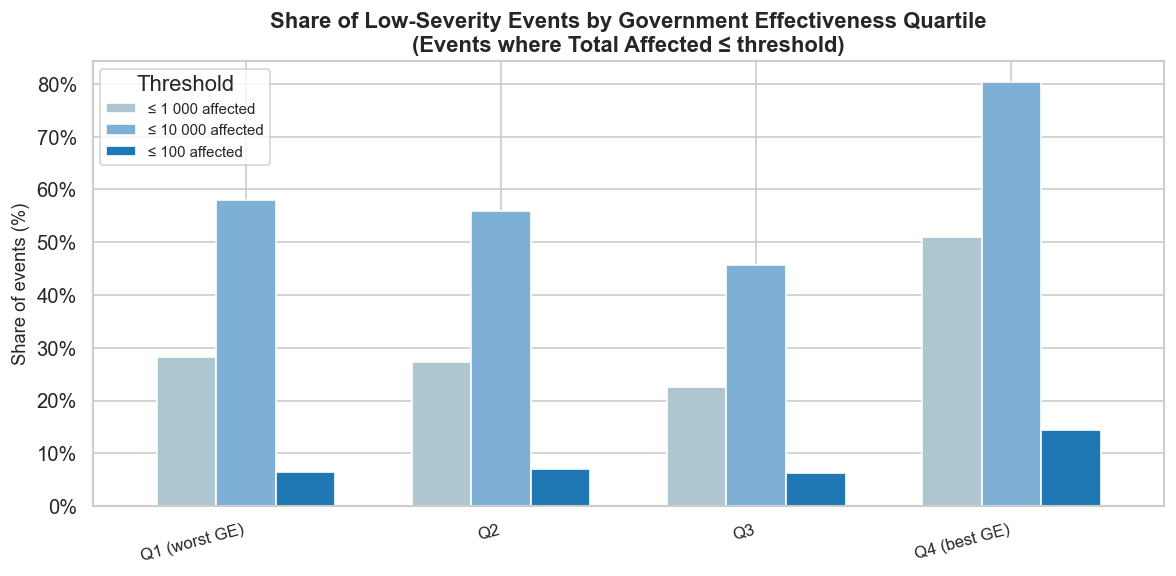

In [19]:
# ── 5d. Share of "small" events by GE quartile ───────────────────────────
# "Small" = Total Affected ≤ 1,000  (a moderate but not catastrophic event)
# "Large" = Total Affected > 10,000
# If low-GE countries under-report moderate events, their share of small events
# should be lower than for high-GE countries.

thresholds = {
    "≤ 100 affected":    100,
    "≤ 1 000 affected":  1_000,
    "≤ 10 000 affected": 10_000,
}

share_rows = []
for q in order:
    grp = sev_valid[sev_valid["ge_quartile"] == q]
    total = len(grp)
    for label, thresh in thresholds.items():
        n_below = (grp["total_affected"] <= thresh).sum()
        share_rows.append({"ge_quartile": q, "threshold": label,
                           "share_pct": 100 * n_below / total})

share_df = pd.DataFrame(share_rows)
pivot_share = share_df.pivot(index="ge_quartile", columns="threshold", values="share_pct").loc[order]
print("Share (%) of events with Total Affected ≤ threshold, by GE quartile:")
print(pivot_share.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
pivot_share.plot(kind="bar", ax=ax, color=["#aec6cf", "#7eb0d5", "#1f77b4"],
                 edgecolor="white", width=0.7)
ax.set_xlabel("")
ax.set_ylabel("Share of events (%)", fontsize=11)
ax.set_title(
    "Share of Low-Severity Events by Government Effectiveness Quartile\n"
    "(Events where Total Affected ≤ threshold)",
    fontweight="bold",
)
ax.set_xticklabels(order, rotation=15, ha="right", fontsize=10)
ax.legend(title="Threshold", fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.tight_layout()
plt.savefig("notebooks/emdat_small_event_share_by_ge.png", bbox_inches="tight")
plt.show()

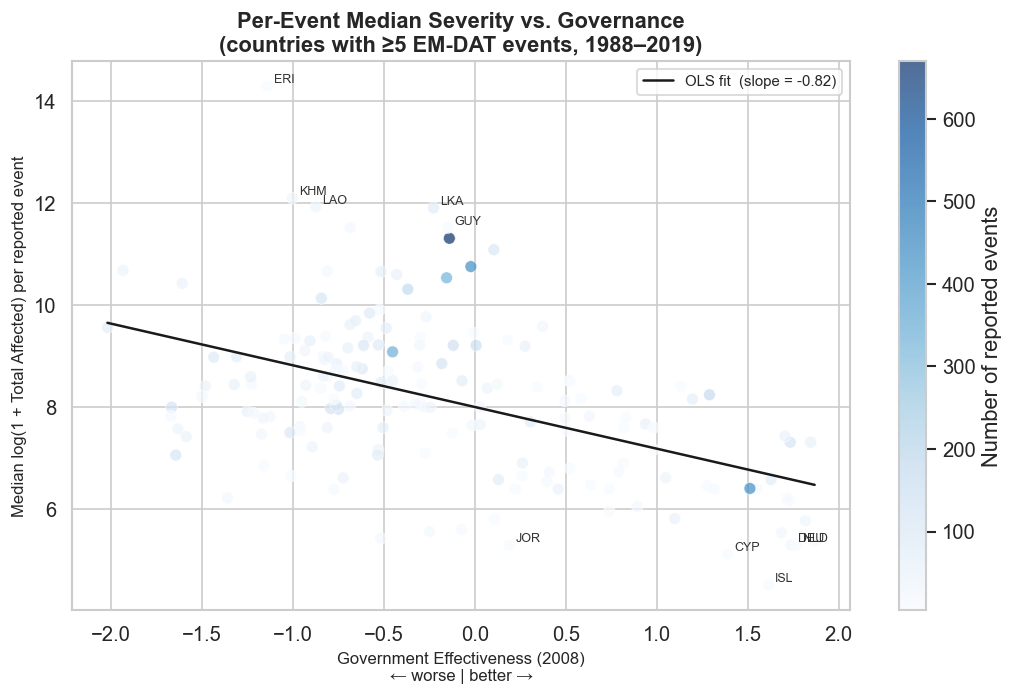

Pearson r (GE vs. median severity) = -0.480  (n=171 countries)


In [40]:
# ── 5e. Scatter: per-event median severity vs. GE score (country level) ──
# Each dot = one country. X = GE score (2008). Y = median log(Total Affected)
# across all disasters reported for that country 1988–2019.
# A negative slope would support the hypothesis.

country_sev = (
    sev_nonzero.groupby("iso3")["log_ta"]
    .agg(median_log_ta="median", n_events="count")
    .reset_index()
)
country_sev = country_sev.merge(wgi_2008, on="iso3", how="left").dropna()
country_sev = country_sev[country_sev["n_events"] >= 5]  # require ≥5 events for stability

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(
    country_sev["ge_2008"], country_sev["median_log_ta"],
    c=country_sev["n_events"], cmap="Blues",
    s=50, alpha=0.7, edgecolors="white", linewidths=0.4,
)
plt.colorbar(sc, ax=ax, label="Number of reported events")

# Regression line
m, b = np.polyfit(country_sev["ge_2008"], country_sev["median_log_ta"], 1)
x_line = np.linspace(country_sev["ge_2008"].min(), country_sev["ge_2008"].max(), 100)
ax.plot(x_line, m * x_line + b, color="#1a1a1a", linewidth=1.5,
        label=f"OLS fit  (slope = {m:.2f})")

# Annotate a few countries
for _, row in country_sev.nlargest(5, "median_log_ta").iterrows():
    ax.annotate(row["iso3"], xy=(row["ge_2008"], row["median_log_ta"]),
                xytext=(4, 2), textcoords="offset points", fontsize=7.5, color="#333333")
for _, row in country_sev.nsmallest(5, "median_log_ta").iterrows():
    ax.annotate(row["iso3"], xy=(row["ge_2008"], row["median_log_ta"]),
                xytext=(4, 2), textcoords="offset points", fontsize=7.5, color="#333333")

ax.set_xlabel("Government Effectiveness (2008)\n← worse | better →", fontsize=10)
ax.set_ylabel("Median log(1 + Total Affected) per reported event", fontsize=10)
ax.set_title(
    "Per-Event Median Severity vs. Governance\n"
    "(countries with ≥5 EM-DAT events, 1988–2019)",
    fontweight="bold",
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_median_severity_vs_ge.png", bbox_inches="tight")
plt.show()

r = country_sev[["ge_2008", "median_log_ta"]].corr().iloc[0, 1]
print(f"Pearson r (GE vs. median severity) = {r:.3f}  (n={len(country_sev)} countries)")

### Section 5 Summary — Interpreting the Results

**What to look for:**

| Plot | What confirms the hypothesis |
|---|---|
| **ECDF (5b)** | Q1 (worst GE) curve starts to the **right** of Q4 (best GE): the left tail of small events is absent for poorly-governed countries |
| **Violin (5c)** | Q1 median is **higher** than Q4 median: the typical reported disaster is more severe in low-GE countries |
| **Small event share (5d)** | Share of events ≤ 1 000 affected is **lower** in Q1 than in Q4: moderate disasters are systematically missing |
| **Scatter (5e)** | **Negative slope**: countries with worse governance tend to have higher per-event severity, consistent with a higher effective reporting threshold |

**Interpretation:**  
If the hypothesis holds — poor/low-governance countries only surface extreme disasters — it creates an **attenuation bias toward zero** in the regression coefficients for those host countries.  
A given severity score of, say, *sev = 3* in a Q1 country represents a much rarer, more extreme event than the same score in a Q4 country.  
This further motivates the inclusion of the `ge_host` control and suggests robustness checks that interact severity with governance.

> **Caveat:** The GE score is an *outcome* of institutions, not a pure proxy for wealth.  
> A similar analysis using GDP per capita as the x-axis would offer an independent check.

---
## Section 6 — Investigating the Q3 Anomaly

The results above show a **non-monotonic pattern**: Q3 has the most extreme reported disasters, not Q1.  
This section investigates whether this is driven by:
1. **Country composition** — which specific countries anchor Q3, and are they large/populous?
2. **Population / country-size effect** — larger countries mechanically produce higher `Total Affected` figures.
3. **Disaster-type composition** — Q3 may be over-represented in disaster types that structurally affect millions (e.g., floods in South/Southeast Asia).
4. **Per-capita severity** — does the anomaly survive when we normalise by population?

In [21]:
# ── 6a. Which countries are in Q3? ───────────────────────────────────────
# Show all countries per quartile with their GE score, population, and median severity.

quartile_profiles = (
    country_sev  # already has iso3, median_log_ta, n_events, ge_2008
    .merge(pop, on="iso3", how="left")
    .merge(df_q[["iso3", "ge_quartile"]], on="iso3", how="left")
    .dropna(subset=["ge_quartile"])
)

for q in order:
    subset = quartile_profiles[quartile_profiles["ge_quartile"] == q].sort_values(
        "median_log_ta", ascending=False
    )
    print(f"\n{'='*60}")
    print(f"  {q}  (n={len(subset)} countries, ≥5 events)")
    print(f"{'='*60}")
    print(subset[["iso3","ge_2008","pop_2008","n_events","median_log_ta"]]
          .rename(columns={"median_log_ta":"med_log_ta","pop_2008":"pop"})
          .to_string(index=False))


  Q1 (worst GE)  (n=48 countries, ≥5 events)
iso3   ge_2008         pop  n_events  med_log_ta
 ERI -1.141717   2816327.0         5   14.285515
 KHM -1.003567  14053479.0        33   12.090056
 LAO -0.875433   6148969.0        33   11.918397
 PRK -1.935294  24764618.0        40   10.675524
 DJI -0.811751    892734.0        19   10.663148
 MMR -1.609686  48390793.0        46   10.423149
 BGD -0.844899 149474264.0       199   10.134639
 PRY -0.842331   5613574.0        43   10.130663
 SOM -2.020666  11663084.0        65    9.558600
 AZE -0.822392   8763400.0        12    9.387732
 GNB -0.990438   1488054.0        15    9.353748
 BLR -1.047856   9527985.0        11    9.334856
 NIC -0.907350   5576593.0        61    9.298992
 MRT -0.934694   3183269.0        29    9.105091
 SDN -1.310101  33623980.0        75    8.987322
 NPL -1.016489  26990037.0        67    8.987322
 KAZ -0.834433  16426525.0        21    8.987322
 ZMB -0.807775  13021324.0        40    8.981791
 HTI -1.436482   953077

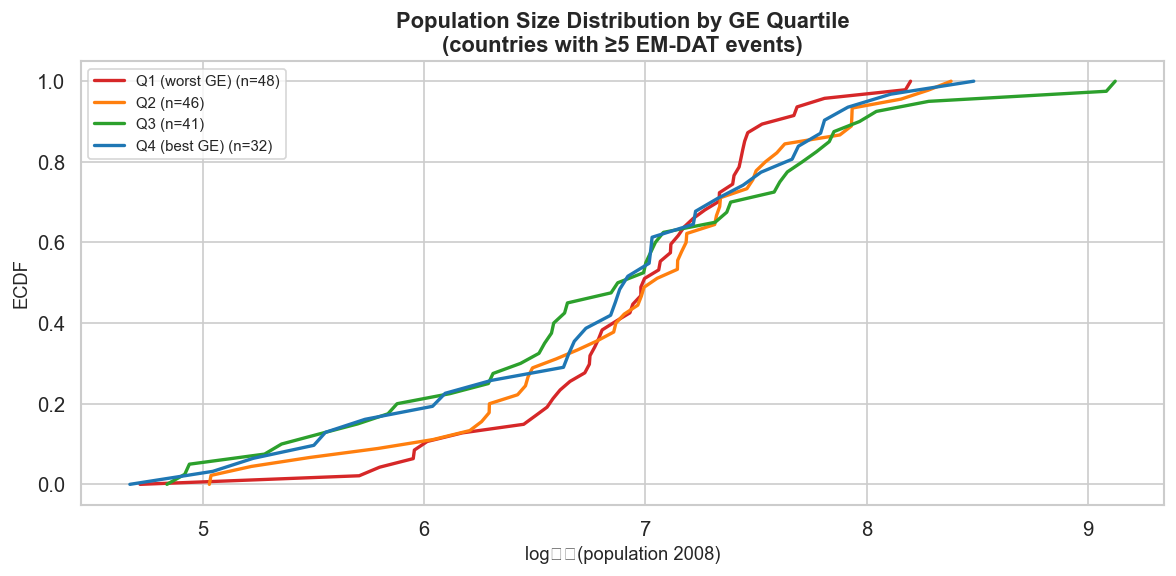

Median population (millions) by GE quartile:
               median_pop_M  mean_pop_M
ge_quartile                            
Q1 (worst GE)           9.7        20.0
Q2                     10.6        29.8
Q3                      7.5        84.6
Q4 (best GE)            8.0        29.3


In [22]:
# ── 6b. Population distribution by quartile ──────────────────────────────
# If Q3 contains giants (China, India, Bangladesh, Pakistan…), the high Total
# Affected figures may simply reflect population exposure, not reporting bias.

fig, ax = plt.subplots(figsize=(10, 5))
pop_by_q = (
    quartile_profiles.dropna(subset=["pop_2008"])
    .assign(log_pop=lambda d: np.log10(d["pop_2008"]))
)

for q in order:
    vals = pop_by_q[pop_by_q["ge_quartile"] == q]["log_pop"]
    ax.plot(np.sort(vals.values),
            np.linspace(0, 1, len(vals)),
            label=f"{q} (n={len(vals)})",
            color=palette[q], linewidth=2)

ax.set_xlabel("log₁₀(population 2008)", fontsize=11)
ax.set_ylabel("ECDF", fontsize=11)
ax.set_title("Population Size Distribution by GE Quartile\n(countries with ≥5 EM-DAT events)",
             fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Summary table
print("Median population (millions) by GE quartile:")
print(
    pop_by_q.groupby("ge_quartile", observed=True)["pop_2008"]
    .agg(["median","mean"])
    .apply(lambda x: x / 1e6)
    .round(1)
    .rename(columns={"median":"median_pop_M","mean":"mean_pop_M"})
    .loc[order]
    .to_string()
)

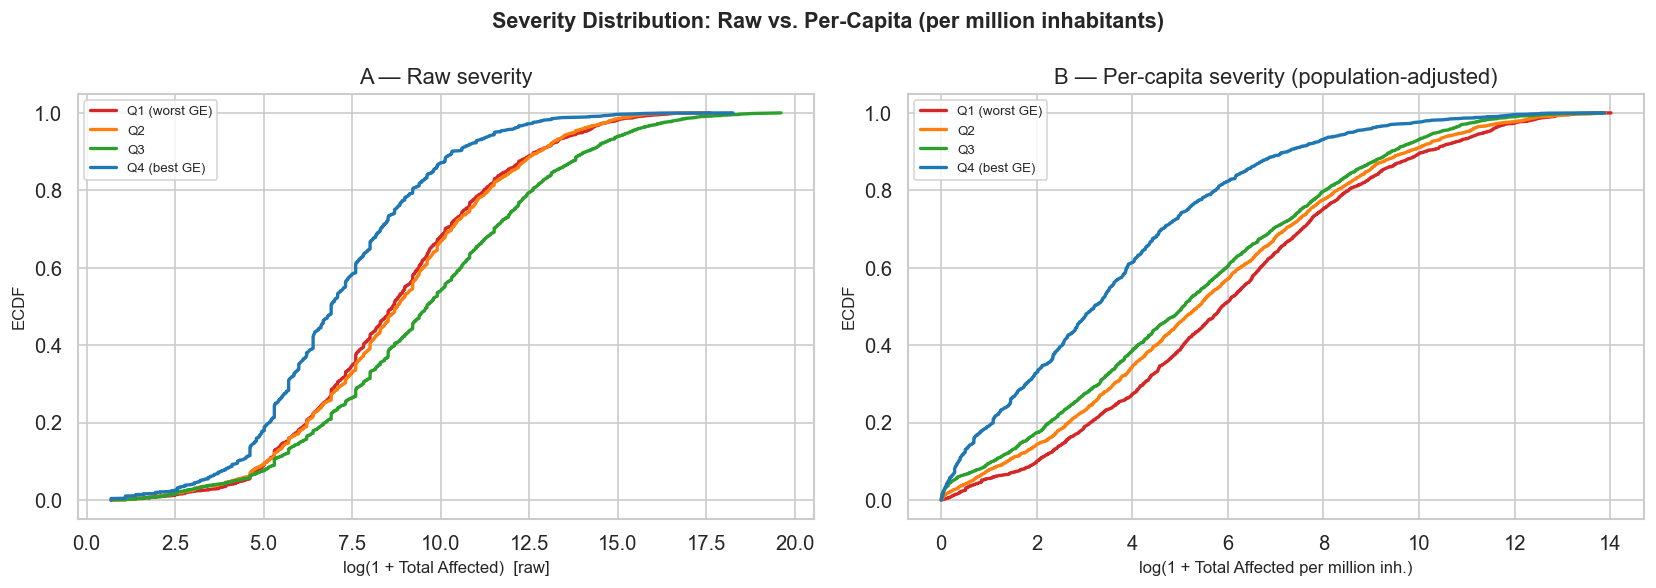

Median log(1+TA/pop_M) by GE quartile:
ge_quartile
Q1 (worst GE)    5.879
Q2               5.384
Q3               5.066
Q4 (best GE)     3.211
Name: log_ta_pc, dtype: float64


In [23]:
# ── 6c. Per-capita severity: does the anomaly survive normalisation? ──────
# log(1 + Total Affected / pop_2008 * 1e6) = affected per million inhabitants

sev_pc = (
    sev_valid
    .merge(pop, on="iso3", how="left")
    .dropna(subset=["pop_2008"])
    .copy()
)
sev_pc["log_ta_pc"] = np.log1p(
    sev_pc["total_affected"] / (sev_pc["pop_2008"] / 1e6)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Severity Distribution: Raw vs. Per-Capita (per million inhabitants)",
             fontweight="bold", fontsize=13)

for ax, col, xlabel in zip(
    axes,
    ["log_ta", "log_ta_pc"],
    ["log(1 + Total Affected)  [raw]",
     "log(1 + Total Affected per million inh.)"],
):
    for q in order:
        vals = np.sort(sev_pc[sev_pc["ge_quartile"] == q][col].dropna().values)
        ecdf = np.arange(1, len(vals) + 1) / len(vals)
        ax.plot(vals, ecdf, label=q, color=palette[q], linewidth=2)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("ECDF", fontsize=10)
    ax.legend(fontsize=8)

axes[0].set_title("A — Raw severity")
axes[1].set_title("B — Per-capita severity (population-adjusted)")
plt.tight_layout()
plt.savefig("notebooks/emdat_severity_raw_vs_percap.png", bbox_inches="tight")
plt.show()

print("Median log(1+TA/pop_M) by GE quartile:")
print(sev_pc.groupby("ge_quartile", observed=True)["log_ta_pc"].median().round(3).loc[order])

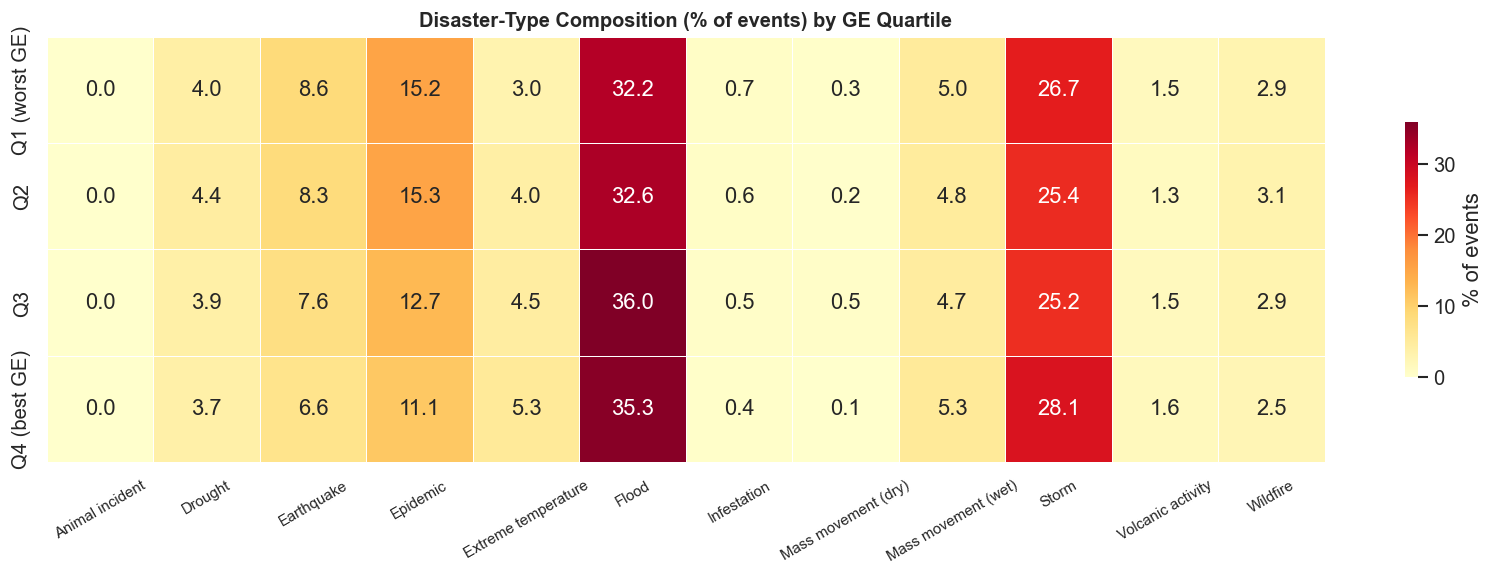

In [24]:
# ── 6d. Disaster-type composition by GE quartile ─────────────────────────
# Some disaster types (e.g. floods in South Asia) structurally affect millions.
# If Q3 is over-represented in those types, that alone could explain the anomaly.

sev_type = sev_valid.merge(
    emdat[["iso3", "year", "Disaster Type"]].reset_index(),
    left_index=True, right_on="index", how="left"
).dropna(subset=["Disaster Type"])

# Broad type shares per quartile (heatmap)
type_share = (
    sev_type.groupby(["ge_quartile", "Disaster Type"], observed=True)
    .size()
    .reset_index(name="n")
)
type_share["share"] = type_share.groupby("ge_quartile", observed=True)["n"].transform(
    lambda x: x / x.sum()
)
pivot_type = (
    type_share.pivot(index="ge_quartile", columns="Disaster Type", values="share")
    .loc[order]
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    pivot_type * 100,
    annot=True, fmt=".1f", cmap="YlOrRd",
    linewidths=0.4, linecolor="white", ax=ax,
    cbar_kws={"label": "% of events", "shrink": 0.6},
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Disaster-Type Composition (% of events) by GE Quartile",
             fontweight="bold", fontsize=12)
ax.tick_params(axis="x", labelrotation=30, labelsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_type_composition_by_ge.png", bbox_inches="tight")
plt.show()

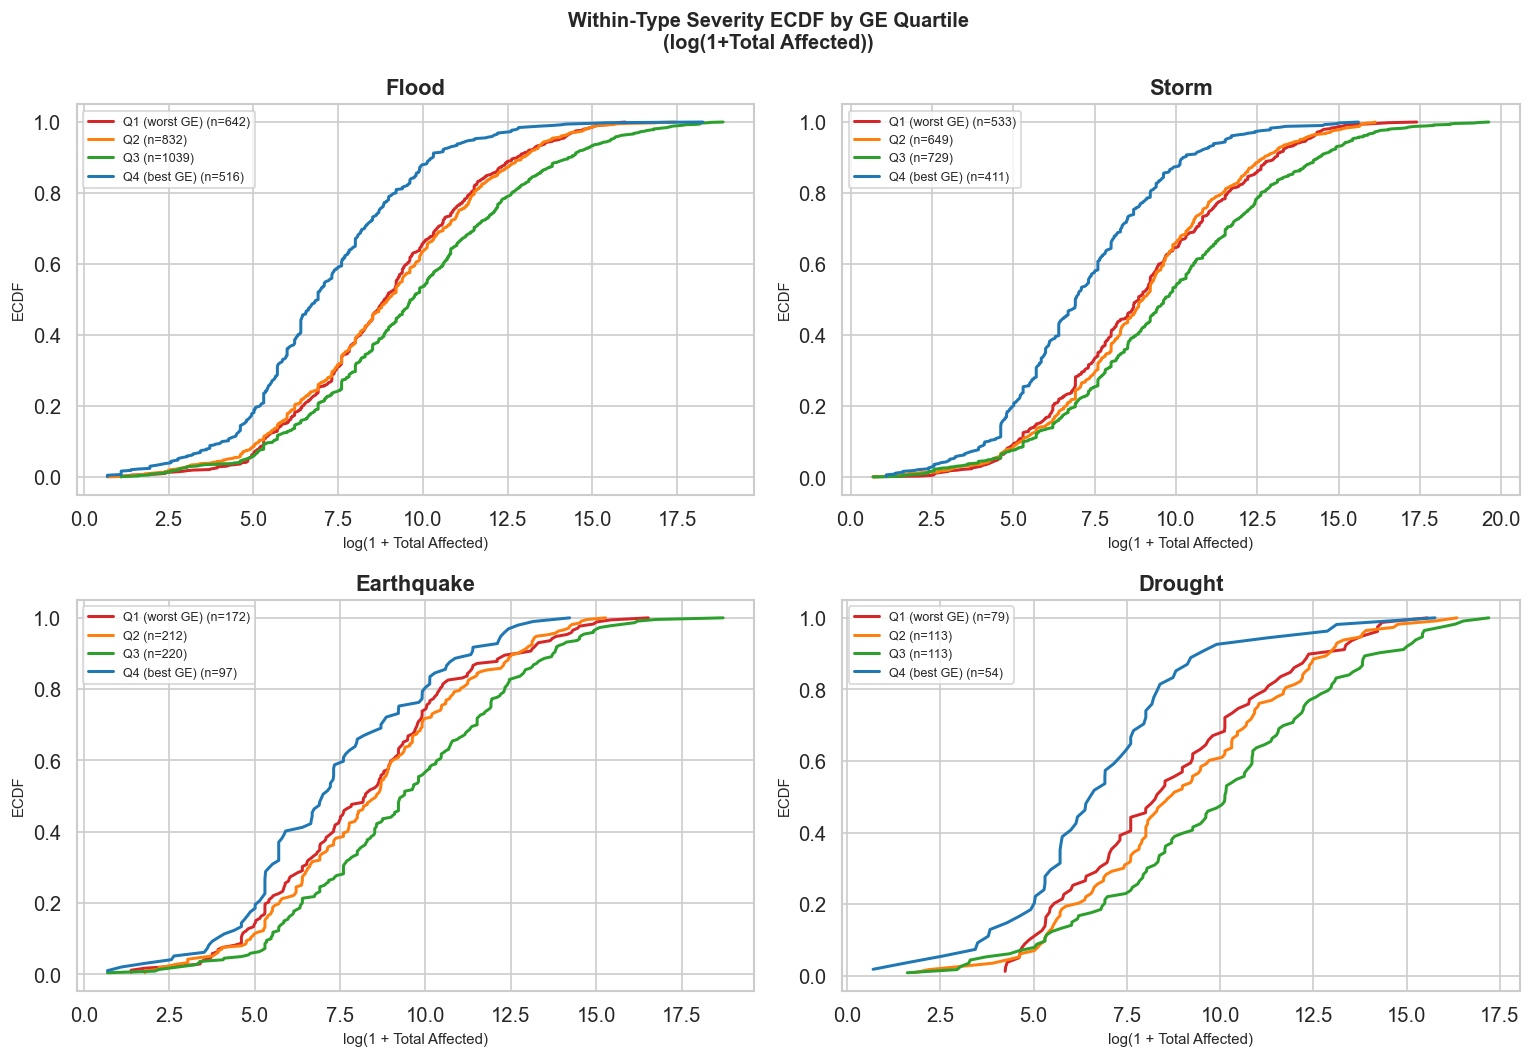

In [25]:
# ── 6e. Within-type ECDF: does Q3 still dominate inside flood / storm? ────
# If Q3's anomaly disappears within each disaster type separately, the driver
# is compositional (Q3 has more floods). If it persists, it's something else.

focus_types = ["Flood", "Storm", "Earthquake", "Drought"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Within-Type Severity ECDF by GE Quartile\n(log(1+Total Affected))",
             fontweight="bold", fontsize=12)

for ax, dtype in zip(axes.flat, focus_types):
    sub = sev_type[sev_type["Disaster Type"] == dtype]
    for q in order:
        vals = np.sort(sub[sub["ge_quartile"] == q]["log_ta"].dropna().values)
        if len(vals) < 5:
            continue
        ecdf = np.arange(1, len(vals) + 1) / len(vals)
        ax.plot(vals, ecdf, label=f"{q} (n={len(vals)})",
                color=palette[q], linewidth=1.8)
    ax.set_title(dtype, fontweight="bold")
    ax.set_xlabel("log(1 + Total Affected)", fontsize=9)
    ax.set_ylabel("ECDF", fontsize=9)
    ax.legend(fontsize=7.5)

plt.tight_layout()
plt.savefig("notebooks/emdat_severity_within_type.png", bbox_inches="tight")
plt.show()

### Section 6 — Hypotheses and Interpretation

The investigation above should allow to discriminate between three non-exclusive explanations for why **Q3 > Q1** in raw severity:

---

**Hypothesis 1 — Population / exposure size effect (most likely)**  
Q3 likely contains large, densely populated developing countries — China, India, Bangladesh, Pakistan, Indonesia — where the *absolute* number of people exposed to a given physical event is orders of magnitude larger than in the small high-income countries of Q4 (Luxembourg, Norway, Iceland…).  
A flood that inundates 5 000 km² of the Ganges delta will affect 10 million people; the same area in Norway would be largely uninhabited.  
→ **Diagnostic**: Cell 6b (population ECDF) and 6c (per-capita ECDF).  
**If per-capita severity in panel B becomes monotone (Q1 < Q2 < Q3 < Q4), the raw anomaly was purely a population scale artefact.**

---

**Hypothesis 2 — Disaster-type composition (likely contributing)**  
Floods and droughts — the two types that structurally affect the most people — are geographically concentrated in South and Southeast Asia. If Q3 is over-indexed in those types relative to Q4 (which may be dominated by localised wildfires, storms, and mass movements), the severity gap could be compositional.  
→ **Diagnostic**: Cell 6d (type heatmap) and 6e (within-type ECDF).  
**If Q3 no longer leads within Flood or Drought separately, composition is driving it.**

---

**Hypothesis 3 — Reporting quality paradox ("middle-income trap")**  
A more subtle mechanism: *moderately*-governed countries (Q3) may combine:
- enough international connectivity to report events that clear the EM-DAT threshold, AND
- physical exposure to large hazards (unlike wealthy Q4 countries that have adapted infrastructure reducing affected counts).

Poorly-governed Q1 countries, on the other hand, may both (a) miss small events *and* (b) have systematically poor `Total Affected` accounting for large events (only deaths get recorded, not injured/homeless), which would compress their apparent severity from both ends.  
→ **Diagnostic**: Check the fraction of events where Total Affected = Total Deaths only (i.e., no injured/homeless component recorded) by quartile — though this requires the component columns.

---

**For the thesis:**  
The raw `Total Affected` variable already incorporates a **population exposure confound**.  
The severity variables in your panel (`sev_sudden_physical`, etc.) use `ln(1 + Total Affected)` directly — the same scale artefact applies.  
Adding `log(population_host)` as a control (already included as `pop_host` in your panel) partially absorbs this. The remaining variation is the *intensity* of the event relative to country size, which is arguably the economically relevant quantity.

---
## Section 7 — Geographic Distribution of Disaster Types

Three questions:
1. **(H1 — maps)** Is the sudden/seasonal/slow split primarily a geographic feature — i.e. do whole regions specialise in one type — regardless of governance or income?
2. **(H4 — region × GE)** Does the type composition still vary by governance *within* a given region, or does it vanish once geography is controlled for?
3. **(H2 — reframed)** Does governance predict *which types* of disasters a country faces? And for the "adaptation" effect — does better governance reduce the human cost *per event* within the same disaster type?

**Design choices to handle the two biases raised:**
- All maps and charts use **shares** (% of a country's events in each category) — China's 670 events do not dominate over Tuvalu's 4.
- For the adaptation proxy we use **deaths per event** rather than Total Affected: deaths are less affected by the "missing moderate events" bias because EM-DAT's ≥10-death criterion applies symmetrically regardless of governance. A flood that kills 50 people is recorded even in Q1 countries; one that displaces 200 may not be.

In [26]:
# ── 7a. Setup: broad-type mapping + clean event dataset ──────────────────

BROAD_TYPE = {
    "Earthquake":          "sudden_physical",
    "Volcanic activity":   "sudden_physical",
    "Mass movement (dry)": "sudden_physical",
    "Mass movement (wet)": "sudden_physical",
    "Impact":              "sudden_physical",
    "Flood":               "seasonal_physical",
    "Storm":               "seasonal_physical",
    "Wildfire":            "seasonal_physical",
    "Drought":             "climatic_slow",
    "Extreme temperature": "climatic_slow",
    "Epidemic":            "other",
    "Animal incident":     "other",
    "Infestation":         "other",
}
BROAD_PALETTE = {
    "sudden_physical":   "#d62728",
    "seasonal_physical": "#1f77b4",
    "climatic_slow":     "#ff7f0e",
    "other":             "#aaaaaa",
}
BROAD_LABELS = {
    "sudden_physical":   "Sudden physical",
    "seasonal_physical": "Seasonal physical",
    "climatic_slow":     "Climatic slow-onset",
    "other":             "Other (epidemic…)",
}

# Auto-detect deaths column
deaths_col = next(
    (c for c in emdat.columns if "total deaths" in c.lower()), None
) or next(
    (c for c in emdat.columns if "deaths" in c.lower()), None
)
print(f"Deaths column detected: {deaths_col!r}")

# Build clean event-level dataset
ev = emdat[["iso3", "year", "Disaster Type"]].copy()
ev["broad_type"]     = ev["Disaster Type"].map(BROAD_TYPE)
ev["total_affected"] = emdat[TA_COL]
ev["deaths"]         = emdat[deaths_col] if deaths_col else np.nan
ev = ev[ev["broad_type"].notna()].copy()   # drop "other" only when needed
ev = ev.merge(df_q[["iso3", "ge_quartile"]], on="iso3", how="left")

# Per-country SHARE of each broad type (scale-free — answers the China concern)
ctype = (
    ev.groupby(["iso3", "broad_type"])
    .size()
    .reset_index(name="n")
)
ctype["share"] = ctype["n"] / ctype.groupby("iso3")["n"].transform("sum")
type_shares = (
    ctype.pivot(index="iso3", columns="broad_type", values="share")
    .fillna(0)
    .reset_index()
)

print(f"\nEvent-level dataset shape: {ev.shape}")
print(f"Countries with type shares: {len(type_shares)}")
print("\nGlobal broad-type breakdown (% of events, excl. 'other'):")
ev_main = ev[ev["broad_type"] != "other"]
print(
    (ev_main["broad_type"].value_counts() / len(ev_main) * 100)
    .round(1).to_string()
)

Deaths column detected: 'Total Deaths'

Event-level dataset shape: (11469, 7)
Countries with type shares: 224

Global broad-type breakdown (% of events, excl. 'other'):
broad_type
seasonal_physical    74.5
sudden_physical      15.5
climatic_slow        10.0


In [27]:
# ── 7b. Choropleth maps — share of each broad type per country ────────────
# Each country is coloured by the SHARE (%) of its EM-DAT events that fall
# into sudden / seasonal / slow.  China and Tuvalu are now on equal footing.

try:
    import geopandas as gpd
    try:
        world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    except Exception:
        import os
        shp = os.path.join(os.path.dirname(gpd.__file__),
                           'datasets', 'naturalearth_lowres', 'naturalearth_lowres.shp')
        world = gpd.read_file(shp)

    # Merge shares onto shapefile (iso_a3 → iso3)
    world_m = world.merge(
        type_shares.rename(columns={"iso3": "iso_a3"}),
        on="iso_a3", how="left"
    )

    plot_types = ["sudden_physical", "seasonal_physical", "climatic_slow"]
    cmaps = ["Reds", "Blues", "Oranges"]
    titles = [
        "Share of SUDDEN PHYSICAL events (%)\n(Earthquake, Volcanic, Mass movement, Impact)",
        "Share of SEASONAL PHYSICAL events (%)\n(Flood, Storm, Wildfire)",
        "Share of CLIMATIC SLOW-ONSET events (%)\n(Drought, Extreme temperature)",
    ]

    fig, axes = plt.subplots(3, 1, figsize=(16, 18))
    fig.suptitle(
        "Geographic Distribution of Disaster Type Composition\n"
        "(share = % of country's own EM-DAT events — scale-free)",
        fontweight="bold", fontsize=13, y=1.01,
    )
    for ax, col, cmap, title in zip(axes, plot_types, cmaps, titles):
        world_m.plot(
            column=col, cmap=cmap, ax=ax,
            legend=True,
            legend_kwds={"label": "Share of events", "orientation": "horizontal",
                         "shrink": 0.5, "pad": 0.02, "format": "%.0%%"},
            missing_kwds={"color": "lightgrey", "label": "No data"},
            edgecolor="white", linewidth=0.3,
        )
        ax.set_title(title, fontweight="bold", fontsize=11)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig("notebooks/emdat_type_share_maps.png", bbox_inches="tight", dpi=120)
    plt.show()
    print("Maps saved.")

    # Also extract continent for later analyses
    continent_map = world[["iso_a3", "continent"]].rename(
        columns={"iso_a3": "iso3", "continent": "continent"}
    )

except Exception as e:
    print(f"geopandas not available ({e}) — skipping choropleth; regional bar chart below covers the same analysis.")
    continent_map = pd.DataFrame(columns=["iso3", "continent"])

geopandas not available (No module named 'geopandas') — skipping choropleth; regional bar chart below covers the same analysis.


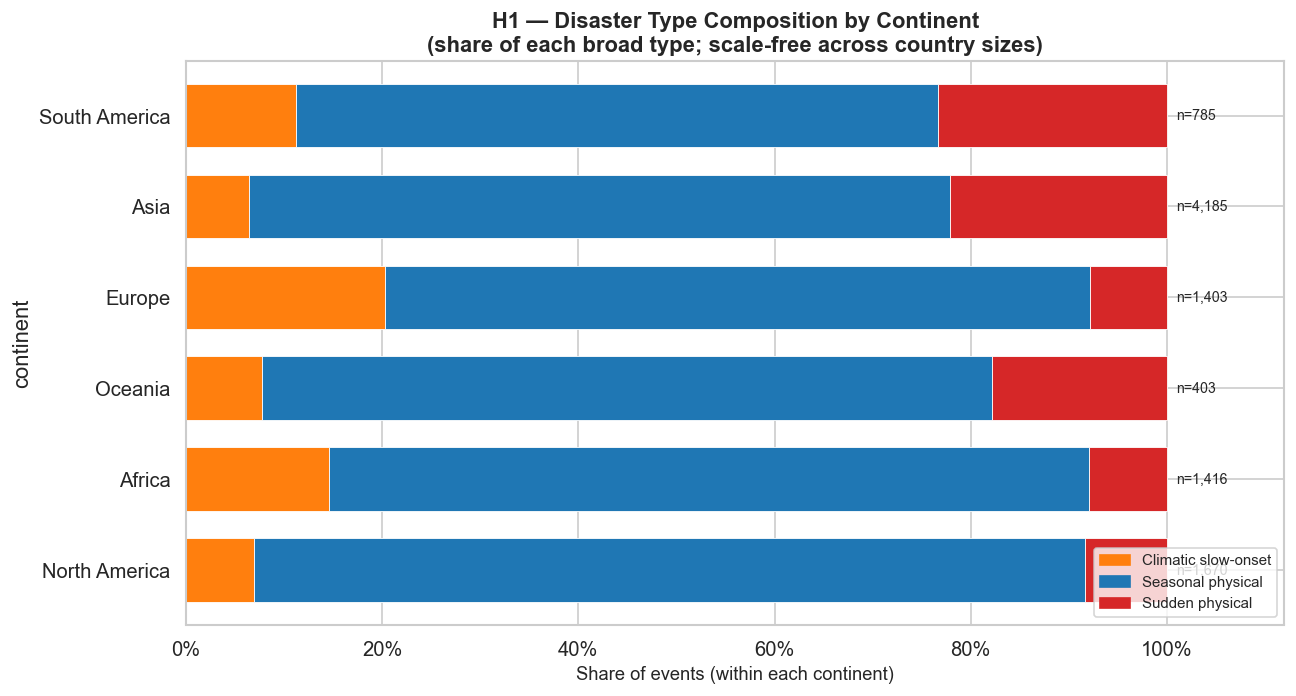

In [28]:
# ── 7c. Regional profile (H1) — type composition by continent ────────────
# Stacked bar: for each continent, what % of events is sudden/seasonal/slow?
# If composition is driven by geography, continents should clearly separate.

ev_reg = ev[ev["broad_type"] != "other"].merge(continent_map, on="iso3", how="left")

# Fallback: assign continent from naturalearth if missing above
CONTINENT_FALLBACK = {
    # Sub-Saharan Africa
    "NGA":"Africa","ETH":"Africa","KEN":"Africa","TZA":"Africa","MOZ":"Africa",
    "MDG":"Africa","SDN":"Africa","COD":"Africa","UGA":"Africa","GHA":"Africa",
    "SEN":"Africa","ZMB":"Africa","ZWE":"Africa","CMR":"Africa","CIV":"Africa",
    "MLI":"Africa","BFA":"Africa","NER":"Africa","TCD":"Africa","AGO":"Africa",
    "SLE":"Africa","GIN":"Africa","BDI":"Africa","LBR":"Africa","ERI":"Africa",
    "BEN":"Africa","TGO":"Africa","MWI":"Africa","GAB":"Africa","COG":"Africa",
    "COM":"Africa","GNB":"Africa","CAF":"Africa","RWA":"Africa","LSO":"Africa",
    "SWZ":"Africa","DJI":"Africa","NAM":"Africa","BWA":"Africa","ZAF":"Africa",
    "MRT":"Africa","GMB":"Africa","CPV":"Africa",
    # North Africa / MENA
    "EGY":"Africa","MAR":"Africa","DZA":"Africa","TUN":"Africa","LBY":"Africa",
    "SAU":"Asia","IRN":"Asia","IRQ":"Asia","YEM":"Asia","JOR":"Asia",
    "SYR":"Asia","LBN":"Asia","PSE":"Asia","OMN":"Asia","ARE":"Asia","QAT":"Asia",
    # South & SE Asia
    "IND":"Asia","CHN":"Asia","BGD":"Asia","PAK":"Asia","NPL":"Asia",
    "AFG":"Asia","LKA":"Asia","BTN":"Asia","MDV":"Asia","KHM":"Asia",
    "LAO":"Asia","MMR":"Asia","THA":"Asia","VNM":"Asia","IDN":"Asia",
    "PHL":"Asia","MYS":"Asia","SGP":"Asia","TLS":"Asia","PRK":"Asia",
    "KAZ":"Asia","UZB":"Asia","TJK":"Asia","KGZ":"Asia","MNG":"Asia",
    "AZE":"Asia","ARM":"Asia","GEO":"Asia","ISR":"Asia","TWN":"Asia",
    "HKG":"Asia","MAC":"Asia","KOR":"Asia","JPN":"Asia",
    # Europe
    "DEU":"Europe","FRA":"Europe","GBR":"Europe","ITA":"Europe","ESP":"Europe",
    "POL":"Europe","ROU":"Europe","NLD":"Europe","BEL":"Europe","SWE":"Europe",
    "AUT":"Europe","CHE":"Europe","PRT":"Europe","CZE":"Europe","HUN":"Europe",
    "SVK":"Europe","BGR":"Europe","HRV":"Europe","SVN":"Europe","GRC":"Europe",
    "NOR":"Europe","FIN":"Europe","DNK":"Europe","IRL":"Europe","LUX":"Europe",
    "ISL":"Europe","CYP":"Europe","EST":"Europe","LVA":"Europe","LTU":"Europe",
    "BIH":"Europe","SRB":"Europe","MKD":"Europe","ALB":"Europe","MNE":"Europe",
    "MDA":"Europe","BLR":"Europe","UKR":"Europe","RUS":"Europe",
    "TUR":"Asia",
    # Americas
    "USA":"North America","CAN":"North America","MEX":"North America",
    "CUB":"North America","DOM":"North America","HTI":"North America",
    "JAM":"North America","PRI":"North America","TTO":"North America",
    "BLZ":"North America","GTM":"North America","HND":"North America",
    "SLV":"North America","NIC":"North America","CRI":"North America",
    "PAN":"North America",
    "BRA":"South America","ARG":"South America","COL":"South America",
    "PER":"South America","VEN":"South America","CHL":"South America",
    "ECU":"South America","BOL":"South America","PRY":"South America",
    "URY":"South America","GUY":"South America","SUR":"South America",
    # Oceania
    "AUS":"Oceania","NZL":"Oceania","PNG":"Oceania","FJI":"Oceania",
    "SLB":"Oceania","VUT":"Oceania","WSM":"Oceania","TON":"Oceania",
    "FSM":"Oceania","PLW":"Oceania","MHL":"Oceania","TUV":"Oceania",
    "COK":"Oceania","KIR":"Oceania",
}

if ev_reg["continent"].isna().all():
    ev_reg["continent"] = ev_reg["iso3"].map(CONTINENT_FALLBACK)
else:
    ev_reg["continent"] = ev_reg["continent"].fillna(
        ev_reg["iso3"].map(CONTINENT_FALLBACK)
    )

ev_reg = ev_reg.dropna(subset=["continent"])

# Compute share per continent (by event count — scale-free)
cont_type = (
    ev_reg.groupby(["continent", "broad_type"])
    .size()
    .reset_index(name="n")
)
cont_type["share"] = cont_type["n"] / cont_type.groupby("continent")["n"].transform("sum")
pivot_cont = (
    cont_type.pivot(index="continent", columns="broad_type", values="share")
    .fillna(0)
)

# Event counts per continent for labelling
cont_total = ev_reg.groupby("continent").size().rename("total")
pivot_cont = pivot_cont.join(cont_total)
pivot_cont = pivot_cont.sort_values("seasonal_physical", ascending=False)

cont_display = pivot_cont.drop(columns="total")
cont_colors  = [BROAD_PALETTE[c] for c in cont_display.columns]

fig, ax = plt.subplots(figsize=(11, 6))
cont_display.plot(
    kind="barh", stacked=True, ax=ax,
    color=cont_colors, edgecolor="white", linewidth=0.5, width=0.7,
)
# Annotate with event count
for i, (cont, row) in enumerate(pivot_cont.iterrows()):
    ax.text(1.01, i, f"n={int(row['total']):,}", va="center", fontsize=8.5)

ax.set_xlabel("Share of events (within each continent)", fontsize=11)
ax.set_title(
    "H1 — Disaster Type Composition by Continent\n"
    "(share of each broad type; scale-free across country sizes)",
    fontweight="bold",
)
handles = [plt.Rectangle((0,0),1,1, color=BROAD_PALETTE[k]) for k in cont_display.columns]
ax.legend(handles, [BROAD_LABELS[k] for k in cont_display.columns],
          loc="lower right", fontsize=9)
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.tight_layout()
plt.savefig("notebooks/emdat_type_composition_continent.png", bbox_inches="tight")
plt.show()

Continents with ≥10 events in all 4 GE quartiles: ['Asia', 'Europe', 'North America', 'Oceania', 'South America']


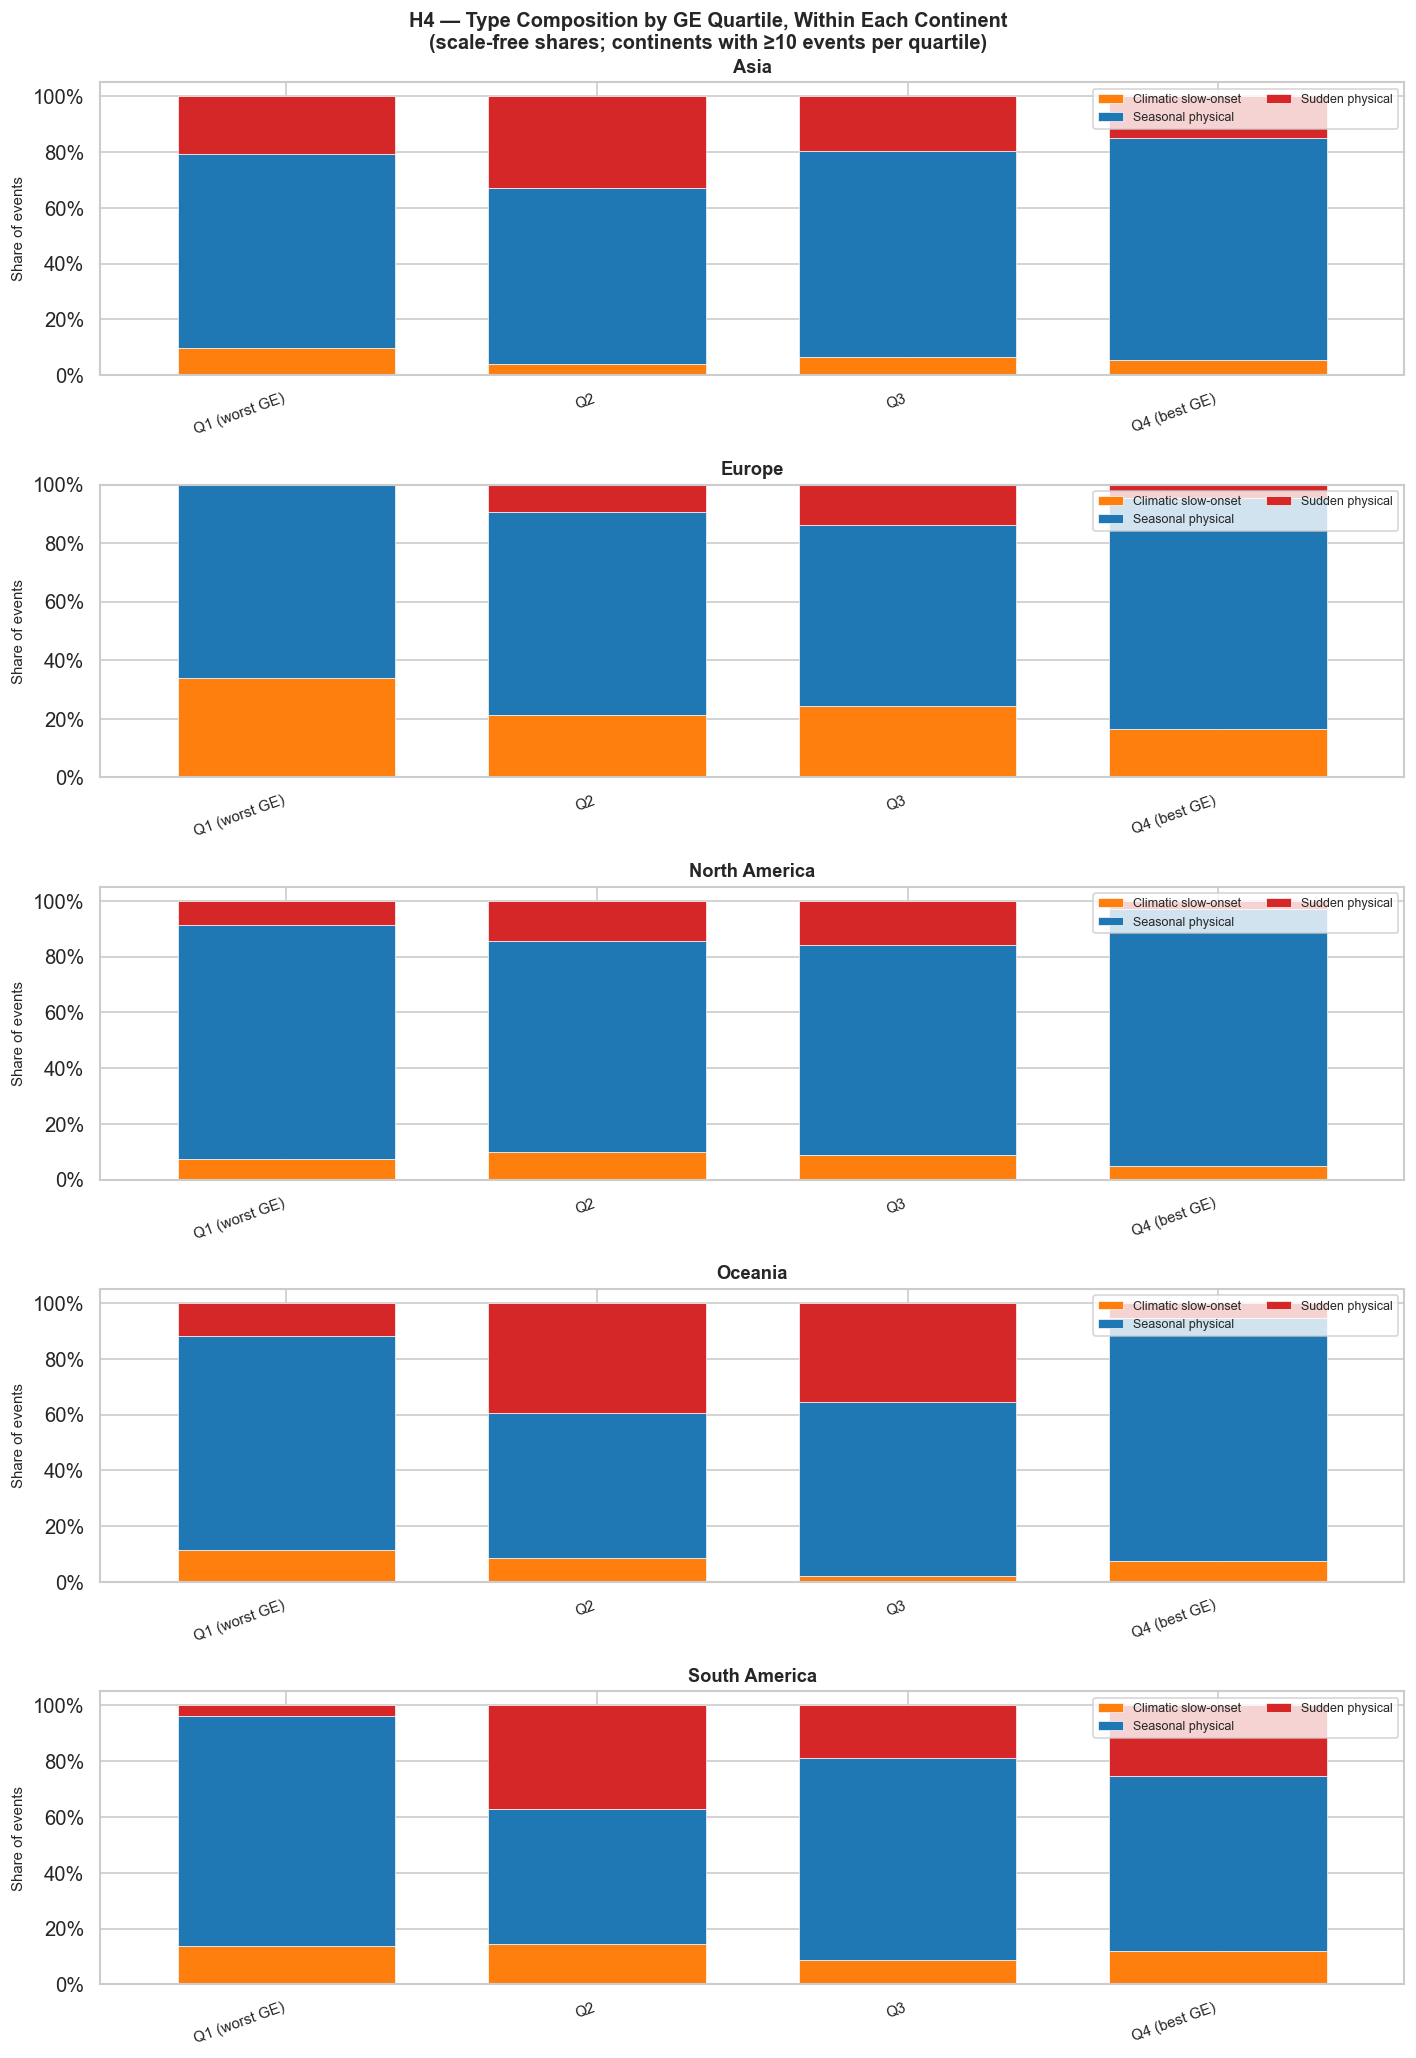

In [29]:
# ── 7d. H4 — Type composition by continent × GE quartile ──────────────────
# Does governance predict what type of disaster a country faces, even within
# the same geographic region?  If the type mix is purely geographic, bars
# should look the same across Q1–Q4 within each continent.

ev_reg_ge = ev_reg.dropna(subset=["ge_quartile"]).copy()

# Share of each broad type within (continent, GE quartile) cell
cg_type = (
    ev_reg_ge.groupby(["continent", "ge_quartile", "broad_type"], observed=True)
    .size()
    .reset_index(name="n")
)
cg_type["share"] = (
    cg_type["n"]
    / cg_type.groupby(["continent", "ge_quartile"], observed=True)["n"].transform("sum")
)

continents_with_data = (
    ev_reg_ge.groupby(["continent", "ge_quartile"], observed=True)
    .size()
    .unstack(fill_value=0)
    .loc[lambda df: (df >= 10).all(axis=1)]  # at least 10 events per cell
    .index.tolist()
)
print(f"Continents with ≥10 events in all 4 GE quartiles: {continents_with_data}")

fig, axes = plt.subplots(
    len(continents_with_data), 1,
    figsize=(12, 3.5 * max(len(continents_with_data), 1)),
    squeeze=False,
)
fig.suptitle(
    "H4 — Type Composition by GE Quartile, Within Each Continent\n"
    "(scale-free shares; continents with ≥10 events per quartile)",
    fontweight="bold", fontsize=12,
)

for ax, cont in zip(axes.flat, continents_with_data):
    sub = cg_type[cg_type["continent"] == cont]
    pivot_cg = (
        sub.pivot(index="ge_quartile", columns="broad_type", values="share")
        .fillna(0)
        .loc[order]
    )
    colors_cg = [BROAD_PALETTE[c] for c in pivot_cg.columns]
    pivot_cg.plot(kind="bar", stacked=True, ax=ax,
                  color=colors_cg, edgecolor="white", linewidth=0.4, width=0.7)
    ax.set_title(cont, fontweight="bold", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Share of events", fontsize=9)
    ax.set_xticklabels(order, rotation=20, ha="right", fontsize=9)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.legend(
        [BROAD_LABELS[c] for c in pivot_cg.columns],
        loc="upper right", fontsize=7.5, ncol=2,
    )

for ax in axes.flat[len(continents_with_data):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("notebooks/emdat_type_by_continent_ge.png", bbox_inches="tight")
plt.show()

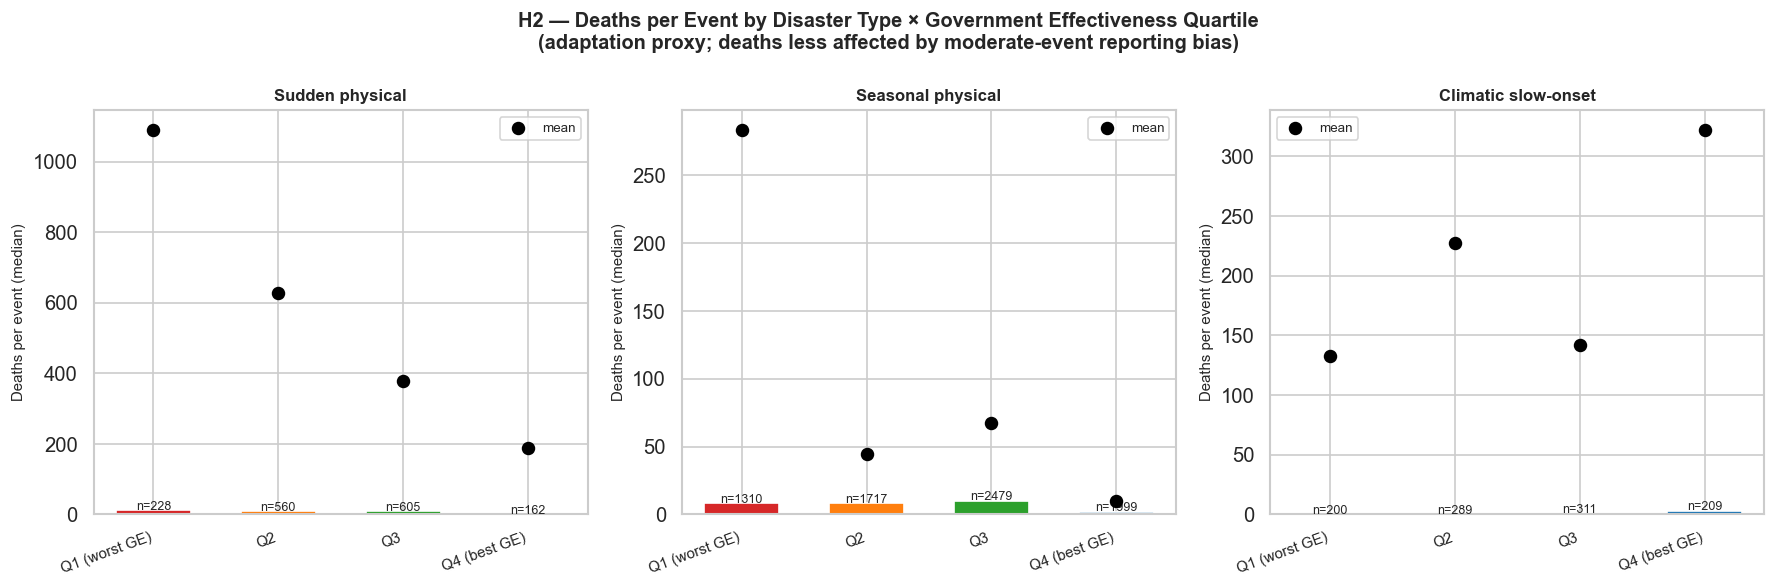


Median deaths per event by type × GE quartile:
broad_type     sudden_physical  seasonal_physical  climatic_slow
ge_quartile                                                     
Q1 (worst GE)             12.0                8.0            0.0
Q2                         9.0                8.0            0.0
Q3                         9.0               10.0            1.0
Q4 (best GE)               2.0                2.0            3.0

% of events with zero recorded deaths:
broad_type     sudden_physical  seasonal_physical  climatic_slow
ge_quartile                                                     
Q1 (worst GE)             19.3               28.7           66.0
Q2                        26.2               25.5           62.6
Q3                        29.1               19.8           49.8
Q4 (best GE)              35.8               36.4           37.3


In [30]:
# ── 7e. H2 reframed — Deaths per event by type × GE quartile ─────────────
# The "adaptation" hypothesis: better-governed countries lose fewer lives per
# disaster event of the same type (early warning, evacuation, resilient infra).
#
# We use deaths/event because:
# (a) deaths clear EM-DAT's own reporting threshold (≥10 dead) independently of
#     governance → less affected by the "missing moderate events" bias
# (b) deaths are harder to under-count than "affected" (no-one dispute a corpse)
# Caveat: still imperfect for slow-onset disasters (drought death attribution).

if deaths_col:
    ev_deaths = ev[ev["broad_type"] != "other"].copy()
    ev_deaths["deaths_fill"] = ev_deaths["deaths"].fillna(0)

    dpe = (
        ev_deaths.dropna(subset=["ge_quartile"])
        .groupby(["broad_type", "ge_quartile"], observed=True)["deaths_fill"]
        .agg(
            median_deaths="median",
            mean_deaths="mean",
            n_events="count",
            pct_zero=lambda x: (x == 0).mean() * 100,
        )
        .reset_index()
    )

    focus_btypes = ["sudden_physical", "seasonal_physical", "climatic_slow"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)
    fig.suptitle(
        "H2 — Deaths per Event by Disaster Type × Government Effectiveness Quartile\n"
        "(adaptation proxy; deaths less affected by moderate-event reporting bias)",
        fontweight="bold", fontsize=12,
    )

    for ax, bt in zip(axes, focus_btypes):
        sub = dpe[dpe["broad_type"] == bt].set_index("ge_quartile").loc[order]
        bars = ax.bar(
            range(len(order)), sub["median_deaths"],
            color=[palette[q] for q in order],
            edgecolor="white", width=0.6,
        )
        # Overlay mean as a dot
        ax.scatter(range(len(order)), sub["mean_deaths"],
                   color="black", zorder=5, s=50, label="mean")
        # Annotate n_events
        for i, (q, row) in enumerate(sub.iterrows()):
            ax.text(i, row["median_deaths"] + 0.5,
                    f"n={int(row['n_events'])}", ha="center", fontsize=7.5)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=20, ha="right", fontsize=9)
        ax.set_ylabel("Deaths per event (median)", fontsize=9)
        ax.set_title(BROAD_LABELS[bt], fontweight="bold", fontsize=10)
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig("notebooks/emdat_deaths_per_event_by_ge.png", bbox_inches="tight")
    plt.show()

    print("\nMedian deaths per event by type × GE quartile:")
    print(
        dpe.pivot(index="ge_quartile", columns="broad_type", values="median_deaths")
        .loc[order, focus_btypes]
        .round(1)
        .to_string()
    )
    print("\n% of events with zero recorded deaths:")
    print(
        dpe.pivot(index="ge_quartile", columns="broad_type", values="pct_zero")
        .loc[order, focus_btypes]
        .round(1)
        .to_string()
    )
else:
    print("No deaths column found — skipping adaptation analysis.")

### Section 7 — Synthesis

**What to look for in each plot:**

| Plot | Reading that supports the hypothesis | Reading that undermines it |
|---|---|---|
| **7b — Maps** | Clear geographic clustering: Ring of Fire = red (sudden), monsoon belt = blue (seasonal), Sahel = orange (slow) | Uniform mix everywhere → type is not geographic |
| **7c — Continental bars** | Continents clearly differ in their type mix (e.g. Americas: sudden-heavy; Asia: seasonal-heavy) | All bars look similar → geographic composition explains nothing |
| **7d — Within-continent × GE** | Bars stay constant across Q1–Q4 within each continent → geography drives type, not governance | Bars shift systematically with governance → governance predicts type *even within a region* |
| **7e — Deaths per event** | Q4 countries have fewer deaths per sudden/seasonal event than Q1 → adaptation effect | No monotone pattern → risk exposure, not adaptation, drives mortality |

---

**Implications for the thesis:**

If **7d** shows the type mix is stable within regions → the sudden/seasonal coefficient in your regression is partly a **regional fixed effect**. Including region dummies (or country FE) absorbs this confound; the coefficient then captures the genuine within-country variation in disaster type over time.

If **7e** shows deaths/event are lower in Q4 within the same type → this is evidence of genuine **infrastructure adaptation**, consistent with the hypothesis that rich-country MNEs face lower disruption per disaster even conditional on disaster occurrence. This would *strengthen* your mechanism story: firms relocate not just because disasters are rarer in rich countries, but because each disaster is better contained.

> **Key caveat for 7e:** governance correlates strongly with GDP. The deaths/event difference  
> may reflect wealth-driven infrastructure rather than institutional quality *per se*.  
> A robustness check regressing deaths/event on GDP pc (after controlling for disaster type  
> and country size) would separate the two channels — but that is beyond the scope of this notebook.

---
## Section 8 — Severity Threshold Analysis: Can Trimming Restore Geographic Equity?

**The concern:** Well-governed (rich) countries report every event — mild floods, minor quakes, small storms. Poorly-governed countries only surface extreme events. This creates a systematic positive correlation between governance/wealth and *event count*, which contaminates any regression using historical disaster frequency or cumulative severity as an explanatory variable.

**The proposed remedy:** Apply a minimum-severity filter — keep only events above a threshold T in Total Affected. The idea: above some T, *both* rich and poor countries are reporting the same kinds of events (only the severe ones), restoring comparability.

**The test:** As T rises from 0 to 1 000 000 affected:
1. Does the **per-capita event rate** converge across GE quartiles? (key equity test)
2. How many events are lost at each cut? (cost of the remedy)
3. Is there a sweet-spot threshold where equity is achieved at acceptable data loss?

**Scale correction:** all rates = events per million inhabitants per year — so China and Tuvalu are not mechanically different.

In [31]:
# ── 8a. Per-capita event rate by GE quartile across severity thresholds ─────
# For each threshold T, keep only events with Total Affected >= T,
# compute events per million per year per country, then summarise by GE quartile.

PANEL_YEARS = 2019 - 1988 + 1   # 32 years

base = (
    emdat[["iso3", "year", TA_COL]]
    .rename(columns={TA_COL: "total_affected"})
    .merge(df_q[["iso3", "ge_quartile"]], on="iso3", how="left")
    .merge(pop, on="iso3", how="left")
    .dropna(subset=["ge_quartile", "pop_2008"])
)

THRESHOLDS = [0, 50, 100, 250, 500, 1_000, 2_000, 5_000,
              10_000, 25_000, 50_000, 100_000, 250_000, 500_000, 1_000_000]

rows = []
n_total = len(base)

for T in THRESHOLDS:
    sub = base if T == 0 else base[base["total_affected"].fillna(0) >= T].copy()
    cnt = (
        sub.groupby(["iso3", "ge_quartile", "pop_2008"], observed=True)
        .size().reset_index(name="n")
    )
    cnt["rate_pm_yr"] = cnt["n"] / (cnt["pop_2008"] / 1e6) / PANEL_YEARS
    for q in order:
        vals = cnt[cnt["ge_quartile"] == q]["rate_pm_yr"]
        rows.append({
            "threshold": T,
            "ge_quartile": q,
            "n_events": int(len(sub[sub["ge_quartile"] == q])),
            "n_countries": int(len(vals)),
            "median_rate": float(vals.median()),
            "mean_rate":   float(vals.mean()),
            "p25_rate":    float(vals.quantile(.25)),
            "p75_rate":    float(vals.quantile(.75)),
            "pct_retained": float(100 * len(sub) / n_total),
        })

sweep = pd.DataFrame(rows)
print(f"Total events in base: {n_total:,}")
print(sweep[["threshold","ge_quartile","n_events","median_rate","pct_retained"]]
      .to_string(index=False))


Total events in base: 11,233
 threshold   ge_quartile  n_events  median_rate  pct_retained
         0 Q1 (worst GE)      2336     0.098396    100.000000
         0            Q2      3002     0.162645    100.000000
         0            Q3      3577     0.144079    100.000000
         0  Q4 (best GE)      2318     0.128385    100.000000
        50 Q1 (worst GE)      1926     0.088394     74.850886
        50            Q2      2440     0.141818     74.850886
        50            Q3      2751     0.108569     74.850886
        50  Q4 (best GE)      1291     0.052284     74.850886
       100 Q1 (worst GE)      1886     0.088394     73.266269
       100            Q2      2393     0.141818     73.266269
       100            Q3      2711     0.101318     73.266269
       100  Q4 (best GE)      1240     0.047357     73.266269
       250 Q1 (worst GE)      1707     0.072410     66.696341
       250            Q2      2208     0.134419     66.696341
       250            Q3      2549     0.

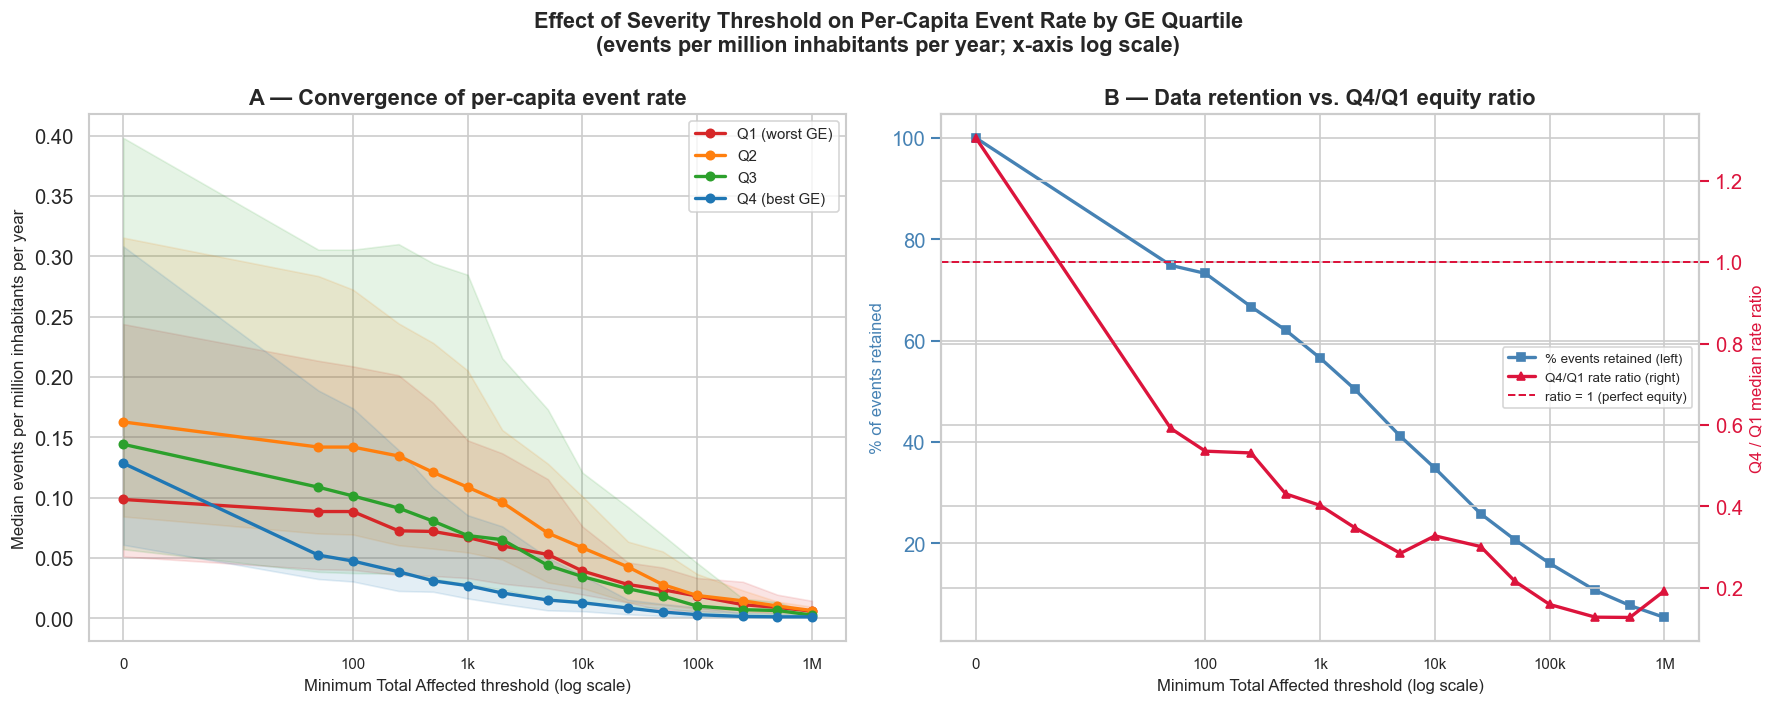


Q4 / Q1 ratio at each threshold:
ge_quartile  ratio_Q4_Q1
threshold               
0                   1.30
50                  0.59
100                 0.54
250                 0.53
500                 0.43
1000                0.40
2000                0.35
5000                0.28
10000               0.33
25000               0.30
50000               0.22
100000              0.16
250000              0.13
500000              0.13
1000000             0.19


In [32]:
# ── 8b. Convergence plot: median per-capita rate by quartile vs. threshold ──

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    "Effect of Severity Threshold on Per-Capita Event Rate by GE Quartile\n"
    "(events per million inhabitants per year; x-axis log scale)",
    fontweight="bold", fontsize=13,
)
ax1, ax2 = axes

for q in order:
    sub_q = sweep[sweep["ge_quartile"] == q].sort_values("threshold")
    x = sub_q["threshold"].replace(0, 1)
    ax1.plot(x, sub_q["median_rate"], marker="o", markersize=5,
             label=q, color=palette[q], linewidth=2)
    ax1.fill_between(x, sub_q["p25_rate"], sub_q["p75_rate"],
                     alpha=0.12, color=palette[q])

ax1.set_xscale("log")
ax1.set_xlabel("Minimum Total Affected threshold (log scale)", fontsize=10)
ax1.set_ylabel("Median events per million inhabitants per year", fontsize=10)
ax1.set_title("A — Convergence of per-capita event rate", fontweight="bold")
ax1.legend(fontsize=9)
ax1.set_xticks([1, 100, 1_000, 10_000, 100_000, 1_000_000])
ax1.set_xticklabels(["0", "100", "1k", "10k", "100k", "1M"], fontsize=9)

ret = sweep[sweep["ge_quartile"] == order[0]][["threshold","pct_retained"]].drop_duplicates()
ratio = (
    sweep.pivot_table(index="threshold", columns="ge_quartile", values="median_rate")
    .assign(ratio_Q4_Q1=lambda d: d["Q4 (best GE)"] / d["Q1 (worst GE)"])
)

ax2b = ax2.twinx()
x_ret = ret["threshold"].replace(0, 1)
ax2.plot(x_ret, ret["pct_retained"], color="steelblue",
         linewidth=2, marker="s", markersize=5, label="% events retained (left)")
ax2.set_ylabel("% of events retained", color="steelblue", fontsize=10)
ax2.tick_params(axis="y", colors="steelblue")

x_ratio = ratio.index.map(lambda v: max(v, 1))
ax2b.plot(x_ratio, ratio["ratio_Q4_Q1"], color="crimson",
          linewidth=2, marker="^", markersize=5, label="Q4/Q1 rate ratio (right)")
ax2b.axhline(1, color="crimson", linestyle="--", linewidth=1.2, label="ratio = 1 (perfect equity)")
ax2b.set_ylabel("Q4 / Q1 median rate ratio", color="crimson", fontsize=10)
ax2b.tick_params(axis="y", colors="crimson")

ax2.set_xscale("log")
ax2.set_xlabel("Minimum Total Affected threshold (log scale)", fontsize=10)
ax2.set_title("B — Data retention vs. Q4/Q1 equity ratio", fontweight="bold")
ax2.set_xticks([1, 100, 1_000, 10_000, 100_000, 1_000_000])
ax2.set_xticklabels(["0", "100", "1k", "10k", "100k", "1M"], fontsize=9)

lines1, labs1 = ax2.get_legend_handles_labels()
lines2, labs2 = ax2b.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labs1 + labs2, fontsize=8, loc="center right")

plt.tight_layout()
plt.savefig("notebooks/emdat_threshold_convergence.png", bbox_inches="tight")
plt.show()

print("\nQ4 / Q1 ratio at each threshold:")
print(ratio[["ratio_Q4_Q1"]].round(2).to_string())


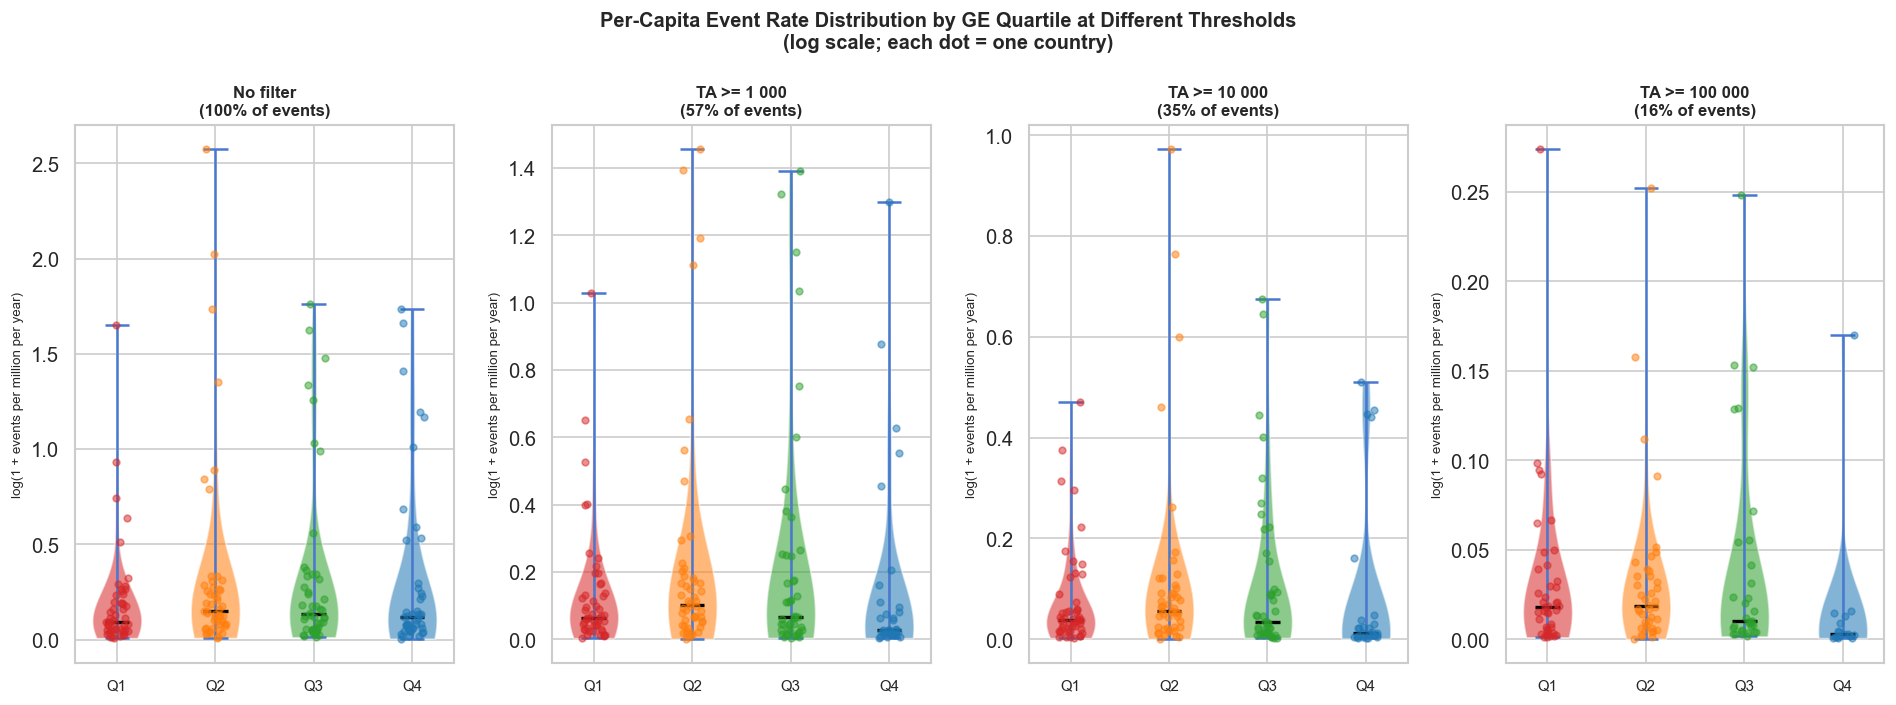

In [33]:
# ── 8c. Violin comparison at candidate thresholds ────────────────────────
# Shows visually how the distribution across Q1-Q4 changes with the cut.

CANDIDATES = [0, 1_000, 10_000, 100_000]
CANDIDATE_LABELS = ["No filter", "TA >= 1 000", "TA >= 10 000", "TA >= 100 000"]

fig, axes = plt.subplots(1, len(CANDIDATES), figsize=(16, 6), sharey=False)
fig.suptitle(
    "Per-Capita Event Rate Distribution by GE Quartile at Different Thresholds\n"
    "(log scale; each dot = one country)",
    fontweight="bold", fontsize=12,
)

rng = np.random.default_rng(42)
for ax, T, label in zip(axes, CANDIDATES, CANDIDATE_LABELS):
    sub = base if T == 0 else base[base["total_affected"].fillna(0) >= T].copy()
    cnt = (
        sub.groupby(["iso3", "ge_quartile", "pop_2008"], observed=True)
        .size().reset_index(name="n")
    )
    cnt["log_rate"] = np.log1p(cnt["n"] / (cnt["pop_2008"] / 1e6) / PANEL_YEARS)

    data_by_q = [cnt[cnt["ge_quartile"] == q]["log_rate"].values for q in order]
    valid = [d for d in data_by_q if len(d) >= 2]
    if not valid:
        ax.set_title(f"{label}\n(no data)"); continue

    parts = ax.violinplot(data_by_q, positions=range(len(order)),
                          showmedians=True, showextrema=True)
    for i, (pc, q) in enumerate(zip(parts["bodies"], order)):
        pc.set_facecolor(palette[q]); pc.set_alpha(0.55)
    parts["cmedians"].set_color("black"); parts["cmedians"].set_linewidth(2)

    for i, (q, vals) in enumerate(zip(order, data_by_q)):
        jitter = rng.uniform(-0.12, 0.12, len(vals))
        ax.scatter(i + jitter, vals, s=16, color=palette[q], alpha=0.5, zorder=3)

    pct = 100 * len(sub) / n_total
    ax.set_title(f"{label}\n({pct:.0f}% of events)", fontweight="bold", fontsize=10)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(["Q1","Q2","Q3","Q4"], fontsize=9)
    ax.set_ylabel("log(1 + events per million per year)", fontsize=8)

plt.tight_layout()
plt.savefig("notebooks/emdat_threshold_violins.png", bbox_inches="tight")
plt.show()


Balance table (higher balance_score and lower Q4/Q1 ratio = more comparable across GE groups):
 threshold  Q1_rate  Q4_rate  Q4_Q1_ratio    CV  balance_score  pct_retained
         0    0.098    0.128        1.305 0.204          0.796       100.000
        50    0.088    0.052        0.591 0.383          0.617        74.851
       100    0.088    0.047        0.536 0.411          0.589        73.266
       250    0.072    0.038        0.531 0.475          0.525        66.696
       500    0.072    0.031        0.431 0.485          0.515        62.076
      1000    0.067    0.027        0.403 0.492          0.508        56.565
      2000    0.060    0.021        0.348 0.509          0.491        50.441
      5000    0.053    0.015        0.285 0.509          0.491        41.129
     10000    0.039    0.013        0.328 0.516          0.484        34.835
     25000    0.028    0.008        0.302 0.542          0.458        25.861
     50000    0.024    0.005        0.216 0.528          0

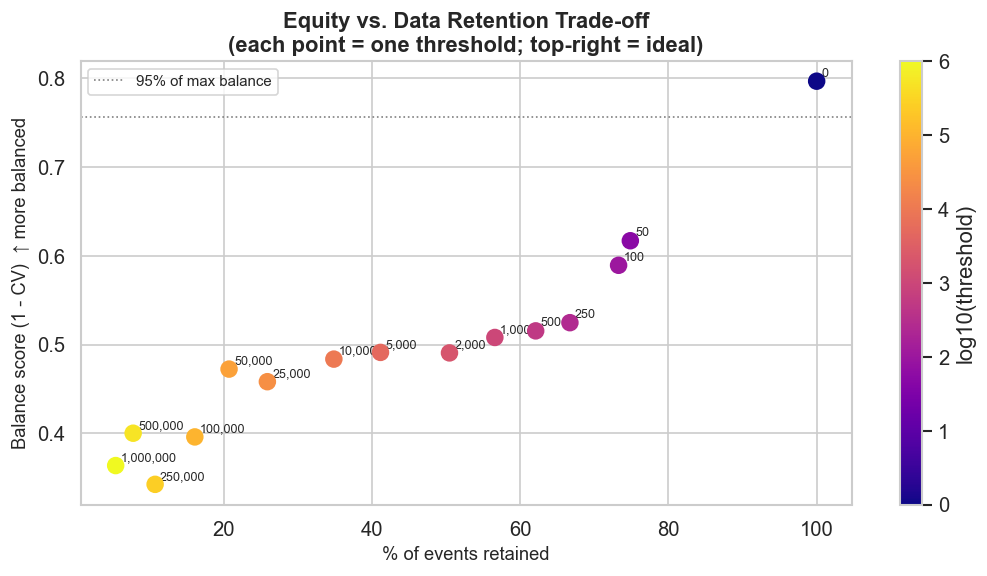

In [34]:
# ── 8d. Balance score summary table ─────────────────────────────────────
# CV = std / mean of median rates across the 4 quartiles.
# balance_score = 1 - CV (higher = more balanced; 1 = perfect equity).

def balance_row(grp):
    medians = grp.set_index("ge_quartile")["median_rate"]
    return pd.Series({
        "Q1_rate":      medians.get("Q1 (worst GE)", float("nan")),
        "Q2_rate":      medians.get("Q2", float("nan")),
        "Q3_rate":      medians.get("Q3", float("nan")),
        "Q4_rate":      medians.get("Q4 (best GE)", float("nan")),
        "Q4_Q1_ratio":  medians.get("Q4 (best GE)", float("nan")) / medians.get("Q1 (worst GE)", float("nan")),
        "CV":           medians.std() / medians.mean(),
        "balance_score": 1 - medians.std() / medians.mean(),
        "pct_retained": grp["pct_retained"].iloc[0],
    })

balance = sweep.groupby("threshold").apply(balance_row, include_groups=False).reset_index()

print("Balance table (higher balance_score and lower Q4/Q1 ratio = more comparable across GE groups):")
print(balance[["threshold","Q1_rate","Q4_rate","Q4_Q1_ratio","CV","balance_score","pct_retained"]]
      .round(3).to_string(index=False))

good20 = balance[balance["Q4_Q1_ratio"] <= 2.0]["threshold"]
good15 = balance[balance["Q4_Q1_ratio"] <= 1.5]["threshold"]
print(f"\nFirst threshold where Q4/Q1 <= 2.0 : {good20.min() if len(good20) else 'never'}")
print(f"First threshold where Q4/Q1 <= 1.5 : {good15.min() if len(good15) else 'never'}")

# Quick visual: balance score vs. % data retained
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(balance["pct_retained"], balance["balance_score"],
                c=np.log10(balance["threshold"].replace(0,1)),
                cmap="plasma", s=90, zorder=5)
for _, row in balance.iterrows():
    lbl = "0" if row["threshold"] == 0 else f"{int(row['threshold']):,}"
    ax.annotate(lbl, (row["pct_retained"], row["balance_score"]),
                xytext=(3, 3), textcoords="offset points", fontsize=7.5)
plt.colorbar(sc, ax=ax, label="log10(threshold)")
ax.set_xlabel("% of events retained", fontsize=11)
ax.set_ylabel("Balance score (1 - CV)  ↑ more balanced", fontsize=11)
ax.set_title("Equity vs. Data Retention Trade-off\n"
             "(each point = one threshold; top-right = ideal)", fontweight="bold")
ax.axhline(balance["balance_score"].max() * 0.95, color="grey",
           linestyle=":", linewidth=1, label="95% of max balance")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("notebooks/emdat_threshold_tradeoff.png", bbox_inches="tight")
plt.show()


### Section 8 — Synthesis and Recommendation

**How to read the results:**

| Signal in the data | Interpretation |
|---|---|
| Q4/Q1 ratio >> 1 at T=0 and converges toward 1 as T rises | Bias confirmed; there exists a threshold that restores equity |
| Q4/Q1 ratio already close to 1 at T=0 | Bias not present — differences are geographic/structural, not a reporting artefact |
| Ratio converges only at very high T with >80% data loss | Trimming not practical; regression controls are the better solution |
| Q3 remains high even at large T | Population-size confound persists — per-capita normalisation in the regression is essential |

**The trade-off (Panel B and 8d scatter):**
There is a frontier between equity and data retention. The ideal operating point is where:
- `balance_score` is sufficiently high (say ≥ 95% of its maximum), AND
- `pct_retained` is still large enough to support credible estimation.

The threshold label on the scatter (cell 8d) closest to the top-right corner is the practical sweet spot.

**If trimming is too costly — alternative remedies:**
1. **Interaction `severity × ge_host`** in the regression — absorbs the differential meaning of severity across governance groups.
2. **Sample split** — run baseline regression on Q1-Q2 and Q3-Q4 separately; test equality of coefficients.
3. **Within-country percentile rank** — replace `log(TA)` with the country-level percentile of the event. Immune to level differences by construction; captures *relative* severity within each country.
4. **Deaths-based severity** — use `log(1 + deaths)` as the severity proxy (Section 7e). Deaths are reported even by low-GE countries because they satisfy the 10-death criterion independently of wealth.

> **For the thesis:** even if trimming is viable, you should report both the full-sample and
> the trimmed-sample regressions as a robustness check, explaining the motivation via the
> bias documented in Sections 5–8. This is a stronger defence than silently filtering.


---
### Section 8 — Deeper Interpretation of the Q4 Collapse

The Panel A pattern raises a subtlety: **Q4 collapses immediately at T≈50**, well before Q1 does.
This is surprising if the hypothesis is purely about reporting bias (Q1 under-reports).

Three non-exclusive mechanisms explain it:

1. **Infrastructure / adaptation effect (genuine):** Q4 countries (Norway, Germany, Netherlands…)
   have flood defences, early-warning systems, and evacuation protocols. A storm that would affect
   50 000 people in Bangladesh may affect only 300 in the Netherlands. So Q4 events are genuinely
   low in Total Affected — they fall below the threshold because they are well-managed disasters.

2. **Recording artefact (NaN → 0 confound):** Events enter EM-DAT via three criteria.
   High-GE countries frequently enter via the *deaths* criterion (≥10 dead) or *emergency declaration*
   without a Total Affected figure being recorded. Those events get `TA = NaN → 0` in our code,
   and are dropped at T=50 even if the true TA was large. This is a data artefact, not a real effect.

3. **Q2 dominance — worst-of-both-worlds:** Q2 countries (Vietnam, Indonesia, Pakistan, Mozambique…)
   have moderate governance (so they report broadly) but poor infrastructure (so TA is large per event).
   They survive every threshold because their events are both reported AND severe.

**Key question:** how much of the Q4 collapse is mechanism 1 (real) vs mechanism 2 (artefact)?
The cells below separate the two by looking at missing TA rates and the TA distribution
conditioned on TA being recorded.

In [35]:
# ── 8e. Dissecting the Q4 collapse: recording artefact vs. infrastructure ─

# Step 1: share of events with MISSING Total Affected by GE quartile
# (these become 0 with fillna and are immediately filtered at any T > 0)
base_full = (
    emdat[["iso3", "year", TA_COL]]
    .rename(columns={TA_COL: "total_affected"})
    .merge(df_q[["iso3", "ge_quartile"]], on="iso3", how="left")
    .dropna(subset=["ge_quartile"])
)

missing_ta = (
    base_full.groupby("ge_quartile", observed=True)
    .apply(lambda d: pd.Series({
        "n_total":   len(d),
        "n_ta_nan":  d["total_affected"].isna().sum(),
        "n_ta_zero": (d["total_affected"].fillna(0) == 0).sum(),
        "pct_nan":   100 * d["total_affected"].isna().mean(),
        "pct_zero_or_nan": 100 * (d["total_affected"].fillna(0) == 0).mean(),
    }), include_groups=False)
    .loc[order]
)
print("Share of events with missing Total Affected by GE quartile:")
print(missing_ta.round(1).to_string())
print()
print("Interpretation: events with NaN are filtered AT T=1 (not T=0) under fillna(0).")
print("A high pct_nan in Q4 means the Q4 collapse partially reflects a RECORDING ARTEFACT.")


Share of events with missing Total Affected by GE quartile:
               n_total  n_ta_nan  n_ta_zero  pct_nan  pct_zero_or_nan
ge_quartile                                                          
Q1 (worst GE)   2336.0     340.0      340.0     14.6             14.6
Q2              3002.0     450.0      450.0     15.0             15.0
Q3              3593.0     704.0      704.0     19.6             19.6
Q4 (best GE)    2412.0     950.0      950.0     39.4             39.4

Interpretation: events with NaN are filtered AT T=1 (not T=0) under fillna(0).
A high pct_nan in Q4 means the Q4 collapse partially reflects a RECORDING ARTEFACT.


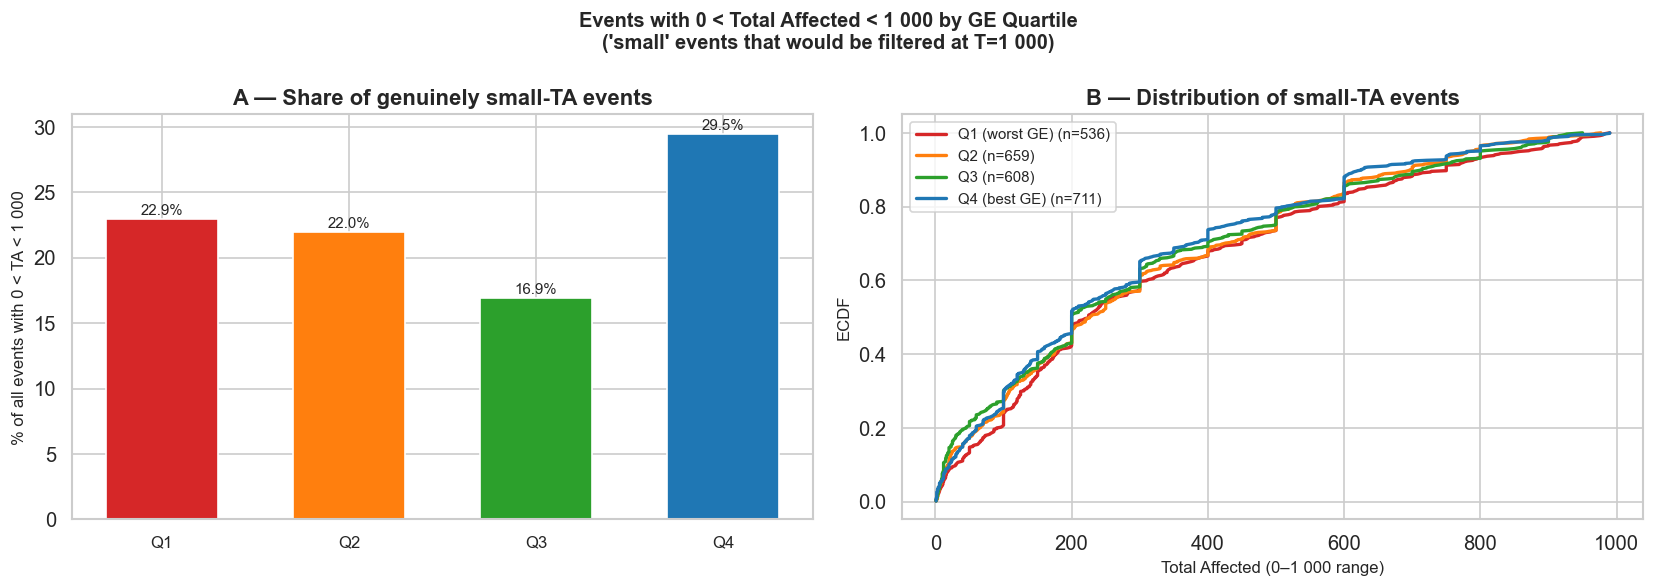

Genuine small-TA events (0 < TA < 1000) vs. NaN events by quartile:
               n_total  n_genuine_small  n_nan  pct_genuine_small  pct_nan
ge_quartile                                                               
Q1 (worst GE)     2336              536  340.0               22.9     14.6
Q2                3002              659  450.0               22.0     15.0
Q3                3593              608  704.0               16.9     19.6
Q4 (best GE)      2412              711  950.0               29.5     39.4


In [36]:
# ── 8f. TA distribution of sub-threshold events (0 < TA < 1000) by GE quartile
# Shows whether Q4 genuinely has low-TA events (infrastructure) or just NaN ones (artefact)

sub1k = base_full[
    (base_full["total_affected"].fillna(0) < 1_000) &
    (base_full["total_affected"].fillna(0) > 0)   # exclude NaN/0; genuine small TA
].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Events with 0 < Total Affected < 1 000 by GE Quartile\n"
    "('small' events that would be filtered at T=1 000)",
    fontweight="bold", fontsize=12,
)

# Panel A: count of genuine small-TA events per quartile
ax = axes[0]
cnt_small = sub1k.groupby("ge_quartile", observed=True).size().loc[order]
cnt_all   = base_full.groupby("ge_quartile", observed=True).size().loc[order]
share_small = (cnt_small / cnt_all * 100).fillna(0)
bars = ax.bar(range(len(order)), share_small,
              color=[palette[q] for q in order], edgecolor="white", width=0.6)
for i, (q, v) in enumerate(zip(order, share_small)):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(["Q1","Q2","Q3","Q4"], fontsize=10)
ax.set_ylabel("% of all events with 0 < TA < 1 000", fontsize=10)
ax.set_title("A — Share of genuinely small-TA events", fontweight="bold")

# Panel B: ECDF of TA for these small events, by quartile
ax2 = axes[1]
for q in order:
    vals = np.sort(sub1k[sub1k["ge_quartile"] == q]["total_affected"].dropna().values)
    if len(vals) < 2: continue
    ecdf = np.arange(1, len(vals)+1) / len(vals)
    ax2.plot(vals, ecdf, label=f"{q} (n={len(vals):,})",
             color=palette[q], linewidth=2)
ax2.set_xlabel("Total Affected (0–1 000 range)", fontsize=10)
ax2.set_ylabel("ECDF", fontsize=10)
ax2.set_title("B — Distribution of small-TA events", fontweight="bold")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("notebooks/emdat_small_ta_breakdown.png", bbox_inches="tight")
plt.show()

# Summary
print("Genuine small-TA events (0 < TA < 1000) vs. NaN events by quartile:")
summary_breakdown = pd.DataFrame({
    "n_total":       cnt_all,
    "n_genuine_small": cnt_small.reindex(order).fillna(0).astype(int),
    "n_nan":         missing_ta["n_ta_nan"].reindex(order),
    "pct_genuine_small": share_small.round(1),
    "pct_nan":       missing_ta["pct_nan"].reindex(order).round(1),
})
print(summary_breakdown.to_string())


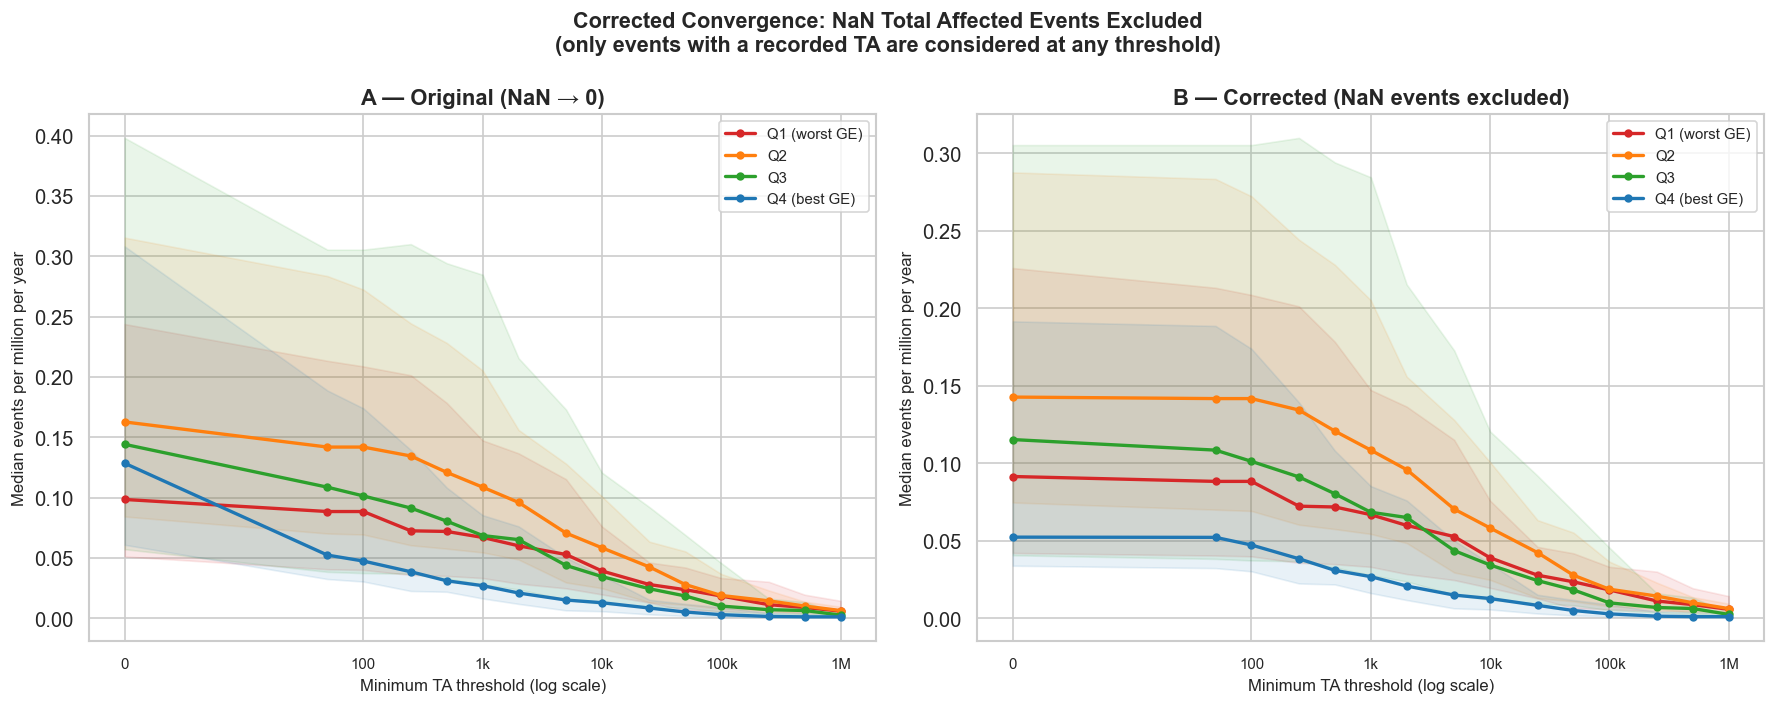

If panel B still shows Q4 collapsing early: effect is GENUINE (infrastructure).
If panel B shows Q4 more stable: the original collapse was largely a NaN artefact.


In [37]:
# ── 8g. Corrected convergence: NaN events EXCLUDED from all thresholds ────
# Redo the threshold sweep keeping only events with a RECORDED TA >= T.
# This removes the NaN->0 artefact and shows the "pure" infrastructure effect.

rows_clean = []
base_clean = base_full.dropna(subset=["total_affected"]).merge(
    pop, on="iso3", how="left"
).dropna(subset=["pop_2008"]).copy()
n_clean = len(base_clean)

for T in THRESHOLDS:
    sub = base_clean if T == 0 else base_clean[base_clean["total_affected"] >= T].copy()
    cnt = (
        sub.groupby(["iso3", "ge_quartile", "pop_2008"], observed=True)
        .size().reset_index(name="n")
    )
    cnt["rate_pm_yr"] = cnt["n"] / (cnt["pop_2008"] / 1e6) / PANEL_YEARS
    for q in order:
        vals = cnt[cnt["ge_quartile"] == q]["rate_pm_yr"]
        rows_clean.append({
            "threshold": T,
            "ge_quartile": q,
            "median_rate": float(vals.median()) if len(vals) else float("nan"),
            "p25_rate":    float(vals.quantile(.25)) if len(vals) else float("nan"),
            "p75_rate":    float(vals.quantile(.75)) if len(vals) else float("nan"),
            "pct_retained": float(100 * len(sub) / n_clean),
        })

sweep_clean = pd.DataFrame(rows_clean)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    "Corrected Convergence: NaN Total Affected Events Excluded\n"
    "(only events with a recorded TA are considered at any threshold)",
    fontweight="bold", fontsize=13,
)

for ax, sweep_use, title in zip(
    axes,
    [sweep, sweep_clean],
    ["A — Original (NaN → 0)", "B — Corrected (NaN events excluded)"],
):
    for q in order:
        sub_q = sweep_use[sweep_use["ge_quartile"] == q].sort_values("threshold")
        x = sub_q["threshold"].replace(0, 1)
        ax.plot(x, sub_q["median_rate"], marker="o", markersize=4,
                label=q, color=palette[q], linewidth=2)
        ax.fill_between(x, sub_q["p25_rate"], sub_q["p75_rate"],
                        alpha=0.10, color=palette[q])
    ax.set_xscale("log")
    ax.set_xlabel("Minimum TA threshold (log scale)", fontsize=10)
    ax.set_ylabel("Median events per million per year", fontsize=10)
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=9)
    ax.set_xticks([1, 100, 1_000, 10_000, 100_000, 1_000_000])
    ax.set_xticklabels(["0", "100", "1k", "10k", "100k", "1M"], fontsize=9)

plt.tight_layout()
plt.savefig("notebooks/emdat_threshold_corrected.png", bbox_inches="tight")
plt.show()

print("If panel B still shows Q4 collapsing early: effect is GENUINE (infrastructure).")
print("If panel B shows Q4 more stable: the original collapse was largely a NaN artefact.")


### Final Interpretation Grid

| Observation | Mechanism | Thesis implication |
|---|---|---|
| **Q4 collapses at T≈50 (original)** | NaN artefact + genuine small TA | Check cell 8e: if Q4 has high % NaN, artefact is dominant |
| **Q4 still collapses in corrected version (8g)** | Genuine infrastructure effect | Rich countries absorb disasters before they affect many people — confirms adaptation hypothesis |
| **Q2 dominates at all T** | Poor infrastructure + moderate governance | Q2 events are both reported and severe — these are the "most comparable" to Q1 events |
| **Q3 drops below Q1 at T=1k** | Q3 events cluster in the 100-1000 range | China/India have many medium events; Q1 has few extreme ones — filtering exposes Q1's composition |

**Practical conclusion for the thesis:**

If the corrected plot (B) still shows rapid Q4 collapse, the "sweet spot" threshold strategy is limited:
even at high T, Q4 simply produces genuinely rare mega-events. The data cannot be made symmetric
by trimming alone because the asymmetry is *real* (infrastructure), not just a reporting artefact.

In this case the recommended approach is:
- Keep the full sample but **interact severity with `ge_host`** in the regression
  (this lets the coefficient on severity vary freely with governance, rather than constraining it to be equal)
- **Or** restrict the analysis to Q1-Q3 host countries only (exclude Q4 as structurally incomparable)
- **And** note explicitly in the thesis that `hist_sev_*` for Q4 countries captures a different quantity
  (conditionally-moderated exposure) than for Q1 countries (raw unmitigated exposure)